# Лабораторная работа № 2. Консолидация разнородных источников: CSV + Excel + JSON → SQLite → аналитика

**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Среда:** один ноутбук Google Colab, без Docker и без внешней СУБД · до 10 баллов за основную часть

## Цель

Собрать данные из трёх источников разного формата, провести аудит и очистку, загрузить результат в локальную реляционную базу SQLite, рассчитать выручку по субъектам и довести результат до управленческих выводов.

## Задачи

1. Прочитать три источника: справочник субъектов (CSV), события с объёмом (Excel) и цены по событиям (JSON).
2. Провести **аудит качества** по шести измерениям: полнота, уникальность, согласованность, валидность, целостность, точность.
3. Очистить данные с ведением **журнала изменений** и карантина: ни одна строка не исчезает молча.
4. Спроектировать схему в SQLite: первичные и внешние ключи, ограничения `CHECK`, индексы.
5. Показать и устранить эффект **fan-out при соединении один-ко-многим** — главную причину завышенной выручки в отчётности.
6. Сверить расчёт на SQL и в pandas, провести аналитику (концентрация, Парето и ABC, сезонность, структура по классам) и сформулировать выводы.
7. **Дополнительно, по желанию:** выгрузить витрину в BigQuery и повторить расчёт (необязательный раздел; основная работа полностью выполняется в SQLite).

## Чем эта работа отличается от версии с Docker и PostgreSQL

| | Прежняя схема | Текущая схема |
|---|---|---|
| Инфраструктура | Docker Compose, контейнер PostgreSQL, Jupyter в контейнере | один ноутбук в Colab |
| СУБД | PostgreSQL 15 на порту 5432 | SQLite: база — один файл рядом с ноутбуком |
| Запуск | установка Docker, `docker compose up`, проброс портов | «Выполнить все» |
| Что теряем | ничего существенного для учебной задачи | — |
| Что приобретаем | — | воспроизводимость, отсутствие проблем с портами и правами |

SQL остаётся тем же: `CREATE TABLE`, ключи, `JOIN`, `GROUP BY`, оконные конструкции и CTE. Отличия SQLite от PostgreSQL, важные для работы, разобраны в теоретическом блоке.

## Что сдаётся

Ноутбук **с выводами ячеек**, файл базы `*.sqlite` и выгрузка витрины, опубликованные в личном репозитории GitHub; в LMS сдаётся ссылка на репозиторий.

## Как выполнять работу

1. **Файл → Сохранить копию на Диске.**
2. В шаге 1 укажите номер варианта, выданный преподавателем. От него зависят предметная область, объём данных и набор дефектов.
3. Выполняйте ячейки сверху вниз: генерация источников → аудит → очистка → SQLite → аналитика → выводы.
4. Перед каждым шагом дано методическое обоснование, после — интерпретация результата. Места с пометкой `TODO` дописываете вы.
5. Раздел BigQuery необязателен. Он включается флагом `ENABLE_BIGQUERY` и требует аккаунта Google Cloud; без него работа выполняется полностью.
6. Перед сдачей запустите самопроверку: должно быть «Выполнено: 11 из 11».

**Важно про данные.** Источники генерируются кодом и намеренно содержат дефекты: дубликаты, пропуски, два формата даты, числа строками с валютой, отрицательные цены, записи с несуществующим внешним ключом. Это не ошибка генератора — это предмет работы. Задача аналитика не в том, чтобы получить красивое число, а в том, чтобы знать, из чего оно посчитано и что было отброшено.

## Теоретический блок

### 1. Консолидация: что это и где ломается

Консолидация — приведение данных из разных источников к единой модели, пригодной для анализа. Типовой конвейер:

```
Извлечение (Extract) → Профилирование → Очистка → Сопоставление ключей → Загрузка (Load) → Витрина → Анализ
```

Три формата, с которыми вы работаете, ведут себя по-разному:

| Формат | Что гарантирует | Типичные проблемы |
|---|---|---|
| **CSV** | ничего, кроме текста | кодировка, разделитель, отсутствие типов: `007` превращается в `7`, а `2025-03-17` — в дату не всегда |
| **Excel** | типы ячеек и автоформатирование | «умное» приведение типов, скрытые пробелы, даты как числа, разные листы и объединённые ячейки |
| **JSON** | структуру и типы | вложенность, разный набор полей у записей, числа строками |

Общее правило: **читать всё как текст и приводить типы явно**. В работе так и сделано — `dtype=str` при чтении, затем контролируемое преобразование.

### 2. Шесть измерений качества данных

| Измерение | Вопрос | Как проверяется в работе |
|---|---|---|
| Полнота | всё ли на месте | доля непустых значений по каждой колонке |
| Уникальность | нет ли дублей | дубликаты строк и повторы ключей |
| Согласованность | одинаково ли записано | два формата даты, числа с валютой и пробелами |
| Валидность | попадает ли в допустимый диапазон | отрицательные цены, нулевой объём |
| Целостность | сходятся ли ссылки между таблицами | события с `entity_id`, которого нет в справочнике |
| Точность | похоже ли на правду | выбросы по правилу 3×IQR |

Принципиальное правило работы: **пропуск не равен нулю**. Замена `NaN` на 0 занижает средние и портит медианы; строка с непригодным значением отправляется в карантин, а не удаляется молча.

### 3. Ключи, кардинальность и fan-out — центральная идея работы

У связи между таблицами есть кардинальность:

* **1 : 1** — одной записи соответствует одна;
* **1 : N** — у события несколько ценовых строк (разные классы);
* **N : M** — требует таблицы-связки.

Если соединить три таблицы «в лоб», строка события повторится столько раз, сколько у него ценовых строк. Это и есть **fan-out**: сумма объёма и выручки завышается кратно.

```
events (1 строка, 180 единиц)      prices (3 строки: 5 000, 12 000, 25 000)
        └──────────── JOIN ────────────┘
результат: 3 строки по 180 единиц → SUM(volume) = 540 вместо 180
```

Правильный порядок действий: **сначала свернуть подчинённую таблицу до уровня родителя (агрегировать цены по событию), потом соединять**. В работе оба варианта считаются и сравниваются численно — вы увидите коэффициент завышения на своих данных.

Формула расчёта после свёртки:

$$
Revenue_{entity} = \sum_{e \in events(entity)} volume_e \cdot \overline{price}_e,
\qquad
\overline{price}_e = \frac{1}{n_e}\sum_{i=1}^{n_e} price_{e,i}
$$

Среднее здесь — упрощение. Если известно количество проданных единиц по каждому классу, корректнее взвешенное среднее; это вынесено в задание со звёздочкой.

### 4. SQLite: что важно знать

SQLite — встраиваемая СУБД: вся база это один файл, сервер не нужен. Именно поэтому она заменяет здесь PostgreSQL в контейнере.

| Особенность | Следствие для работы |
|---|---|
| Внешние ключи **выключены** по умолчанию | обязательно `PRAGMA foreign_keys = ON;` в начале сессии |
| Динамическая типизация (type affinity) | в колонку `INTEGER` можно записать текст: типы контролирует ваш код и `CHECK` |
| Нет отдельного типа `DATE` | даты хранятся строками `YYYY-MM-DD` — формат, который корректно сортируется |
| Нет `TRUE/FALSE` | используйте 0 и 1 |
| Одна запись за раз, читателей много | для учебной задачи и витрин на миллионы строк этого достаточно |
| Поддерживает CTE и оконные функции | `WITH ... AS`, `ROW_NUMBER() OVER (...)` работают как в PostgreSQL |

Чего в SQLite нет по сравнению с PostgreSQL: серверного доступа по сети, ролей и прав, материализованных представлений, параллельной записи, богатых типов (`JSONB`, `ARRAY`, геоданные). Когда эти возможности понадобятся, переносится тот же SQL — меняется строка подключения.

### 5. Три уровня хранения: когда что выбирать

| | SQLite | PostgreSQL | BigQuery |
|---|---|---|---|
| Развёртывание | файл, ноль настройки | сервер или контейнер | облачный сервис |
| Объём | до сотен миллионов строк на одной машине | терабайты | петабайты |
| Модель оплаты | бесплатно | инфраструктура | за объём прочитанных данных |
| Параллельная запись | одна | много | пакетная загрузка |
| Где уместна | прототип, учебная работа, витрина одного аналитика | продуктовая база, многопользовательский доступ | аналитика на больших объёмах, редкие тяжёлые запросы |

Учебная витрина этой работы — десятки тысяч строк. Для неё SQLite избыточно достаточен, и это тоже профессиональный вывод: инструмент выбирается под объём и режим доступа, а не по громкости названия.

### Шаг 1. Окружение и параметры варианта

**Методическое обоснование.** Colab — одноразовая среда: нужные библиотеки проверяются и при необходимости доустанавливаются, рабочая папка создаётся заново. Номер варианта задаёт предметную область, объём генерации и уровень дефектов — от него детерминированно зависят все дальнейшие числа, поэтому результат воспроизводим.

In [1]:
#@title Шаг 1. Окружение и параметры варианта { display-mode: "form" }
VARIANT = 8                 #@param {type:"slider", min:1, max:30, step:1}
ENABLE_BIGQUERY = False      #@param {type:"boolean"}
RANDOM_CHECK = True          #@param {type:"boolean"}

import importlib, json, math, os, re, sqlite3, subprocess, sys, textwrap, warnings
from datetime import datetime, timedelta
from pathlib import Path

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("pandas", "pandas"), ("numpy", "numpy"), ("openpyxl", "openpyxl"),
                 ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.width", 170, "display.max_columns", 50, "display.float_format", "{:,.2f}".format)

WORK = Path("/content/pw2" if Path("/content").exists() else "pw2_work")
DATA = WORK / "data"
DATA.mkdir(parents=True, exist_ok=True)
DB_PATH = WORK / f"consolidation_variant_{VARIANT}.sqlite"

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def nf(x, digits=0):
    """Число с пробелом-разделителем разрядов: 1 234 567."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "—"
    return f"{x:,.{digits}f}".replace(",", " ")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"sqlite3 {sqlite3.sqlite_version}")
print(f"Рабочая папка: {WORK}")

Python 3.12.14 | pandas 3.0.1 | numpy 2.3.5 | sqlite3 3.53.1
Рабочая папка: pw2_work


In [2]:
#@title Шаг 1.1. Конфигурация варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"domain": "Авиаперевозки",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют",
"seed": 1007,
"n_parents": 9,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
},
{
"id": 2,
"domain": "Розничная сеть",
"parent": "Магазины",
"event": "Чеки",
"price": "Позиции чека",
"unit": "единиц товара",
"cls": "категория товара",
"analytics": "ABC-анализ магазинов: какие точки дают 80 % выручки",
"seed": 1014,
"n_parents": 10,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Магазины — CSV, Чеки — XLSX, Позиции чека — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Магазины»"
},
{
"id": 3,
"domain": "Логистика",
"parent": "Перевозчики",
"event": "Отгрузки",
"price": "Тарифы",
"unit": "паллет",
"cls": "тип тарифа",
"analytics": "Загрузка перевозчиков: связь объёма и средней ставки",
"seed": 1021,
"n_parents": 11,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Перевозчики — CSV, Отгрузки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 4,
"domain": "Телеком",
"parent": "Операторы",
"event": "Сессии связи",
"price": "Тарификация",
"unit": "минут",
"cls": "тарифный план",
"analytics": "Доля тарифных планов в выручке и средний чек сессии",
"seed": 1028,
"n_parents": 12,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы — CSV, Сессии связи — XLSX, Тарификация — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 5,
"domain": "Банковский ритейл",
"parent": "Отделения",
"event": "Операции",
"price": "Комиссии",
"unit": "транзакций",
"cls": "тип комиссии",
"analytics": "Эффективность отделений: выручка на одну операцию",
"seed": 1035,
"n_parents": 8,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Отделения — CSV, Операции — XLSX, Комиссии — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отделения»"
},
{
"id": 6,
"domain": "Гостиничный бизнес",
"parent": "Отели",
"event": "Бронирования",
"price": "Тарифы номеров",
"unit": "ночей",
"cls": "категория номера",
"analytics": "Сезонность загрузки и вклад категорий номеров",
"seed": 1042,
"n_parents": 9,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Отели — CSV, Бронирования — XLSX, Тарифы номеров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отели»"
},
{
"id": 7,
"domain": "Образовательные услуги",
"parent": "Центры",
"event": "Группы",
"price": "Стоимость обучения",
"unit": "слушателей",
"cls": "формат обучения",
"analytics": "Выручка на слушателя и сравнение форматов",
"seed": 1049,
"n_parents": 10,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Центры — CSV, Группы — XLSX, Стоимость обучения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Центры»"
},
{
"id": 8,
"domain": "Медицинские клиники",
"parent": "Клиники",
"event": "Приёмы",
"price": "Прейскурант",
"unit": "пациентов",
"cls": "вид услуги",
"analytics": "Структура выручки по видам услуг и загрузка клиник",
"seed": 1056,
"n_parents": 11,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Клиники — CSV, Приёмы — XLSX, Прейскурант — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клиники»"
},
{
"id": 9,
"domain": "Энергосбыт",
"parent": "Сбытовые компании",
"event": "Поставки",
"price": "Тарифы",
"unit": "МВт·ч",
"cls": "категория потребителя",
"analytics": "Концентрация выручки по категориям потребителей",
"seed": 1063,
"n_parents": 12,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Сбытовые компании — CSV, Поставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сбытовые компании»"
},
{
"id": 10,
"domain": "Маркетплейс",
"parent": "Продавцы",
"event": "Заказы",
"price": "Цены товаров",
"unit": "единиц",
"cls": "категория товара",
"analytics": "Топ продавцов и доля категорий в обороте",
"seed": 1070,
"n_parents": 8,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Продавцы — CSV, Заказы — XLSX, Цены товаров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Продавцы»"
},
{
"id": 11,
"domain": "Общественный транспорт",
"parent": "Перевозчики",
"event": "Маршруты-рейсы",
"price": "Тарифы проезда",
"unit": "пассажиров",
"cls": "тип билета",
"analytics": "Выручка по типам билетов и пиковые месяцы",
"seed": 1077,
"n_parents": 9,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Перевозчики — CSV, Маршруты-рейсы — XLSX, Тарифы проезда — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 12,
"domain": "Страхование",
"parent": "Агентства",
"event": "Договоры",
"price": "Тарифные ставки",
"unit": "объектов",
"cls": "вид страхования",
"analytics": "Средняя премия по видам страхования и вклад агентств",
"seed": 1084,
"n_parents": 10,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Агентства — CSV, Договоры — XLSX, Тарифные ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Агентства»"
},
{
"id": 13,
"domain": "Грузовые ж/д перевозки",
"parent": "Операторы вагонов",
"event": "Отправки",
"price": "Ставки",
"unit": "тонн",
"cls": "род груза",
"analytics": "Доходность по родам груза и сезонность отправок",
"seed": 1091,
"n_parents": 11,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы вагонов — CSV, Отправки — XLSX, Ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы вагонов»"
},
{
"id": 14,
"domain": "Общепит",
"parent": "Рестораны",
"event": "Заказы",
"price": "Цены блюд",
"unit": "порций",
"cls": "категория меню",
"analytics": "Средний чек и вклад категорий меню",
"seed": 1098,
"n_parents": 12,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Рестораны — CSV, Заказы — XLSX, Цены блюд — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Рестораны»"
},
{
"id": 15,
"domain": "Фитнес-сети",
"parent": "Клубы",
"event": "Визиты и покупки",
"price": "Прайс услуг",
"unit": "услуг",
"cls": "тип абонемента",
"analytics": "Выручка на клуб и структура абонементов",
"seed": 1105,
"n_parents": 8,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Клубы — CSV, Визиты и покупки — XLSX, Прайс услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клубы»"
},
{
"id": 16,
"domain": "Аренда спецтехники",
"parent": "Парки техники",
"event": "Смены аренды",
"price": "Ставки аренды",
"unit": "машино-часов",
"cls": "тип техники",
"analytics": "Утилизация парка и доходность типов техники",
"seed": 1112,
"n_parents": 9,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Парки техники — CSV, Смены аренды — XLSX, Ставки аренды — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Парки техники»"
},
{
"id": 17,
"domain": "Курьерская доставка",
"parent": "Службы доставки",
"event": "Доставки",
"price": "Тарифы",
"unit": "посылок",
"cls": "скорость доставки",
"analytics": "Доля экспресс-доставки в выручке",
"seed": 1119,
"n_parents": 10,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Службы доставки — CSV, Доставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Службы доставки»"
},
{
"id": 18,
"domain": "Оптовая торговля",
"parent": "Дистрибьюторы",
"event": "Поставки",
"price": "Прайс-листы",
"unit": "коробов",
"cls": "товарная группа",
"analytics": "Парето по товарным группам и вклад дистрибьюторов",
"seed": 1126,
"n_parents": 11,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Дистрибьюторы — CSV, Поставки — XLSX, Прайс-листы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Дистрибьюторы»"
},
{
"id": 19,
"domain": "Автосервис",
"parent": "Сервисные центры",
"event": "Заказ-наряды",
"price": "Прейскурант работ",
"unit": "нормо-часов",
"cls": "вид работ",
"analytics": "Выручка по видам работ и загрузка центров",
"seed": 1133,
"n_parents": 12,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Сервисные центры — CSV, Заказ-наряды — XLSX, Прейскурант работ — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисные центры»"
},
{
"id": 20,
"domain": "Цифровые подписки",
"parent": "Сервисы",
"event": "Подписки",
"price": "Тарифные планы",
"unit": "подписчиков",
"cls": "план подписки",
"analytics": "Структура подписной базы и выручка на подписчика",
"seed": 1140,
"n_parents": 8,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Сервисы — CSV, Подписки — XLSX, Тарифные планы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисы»"
},
{
"id": 21,
"domain": "Сельхозпроизводство",
"parent": "Хозяйства",
"event": "Партии отгрузки",
"price": "Закупочные цены",
"unit": "тонн",
"cls": "культура",
"analytics": "Доходность культур и сезонность отгрузок",
"seed": 1147,
"n_parents": 9,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Хозяйства — CSV, Партии отгрузки — XLSX, Закупочные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Хозяйства»"
},
{
"id": 22,
"domain": "Строительный ритейл",
"parent": "Гипермаркеты",
"event": "Продажи",
"price": "Цены материалов",
"unit": "единиц",
"cls": "группа материалов",
"analytics": "Сезонность продаж и вклад групп материалов",
"seed": 1154,
"n_parents": 10,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Гипермаркеты — CSV, Продажи — XLSX, Цены материалов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Гипермаркеты»"
},
{
"id": 23,
"domain": "Морские перевозки",
"parent": "Судоходные линии",
"event": "Рейсы судов",
"price": "Фрахтовые ставки",
"unit": "TEU",
"cls": "тип контейнера",
"analytics": "Доходность линий и структура по типам контейнеров",
"seed": 1161,
"n_parents": 11,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Судоходные линии — CSV, Рейсы судов — XLSX, Фрахтовые ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Судоходные линии»"
},
{
"id": 24,
"domain": "Аптечные сети",
"parent": "Аптеки",
"event": "Продажи",
"price": "Цены препаратов",
"unit": "упаковок",
"cls": "группа препаратов",
"analytics": "Вклад товарных групп и сравнение точек",
"seed": 1168,
"n_parents": 12,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Аптеки — CSV, Продажи — XLSX, Цены препаратов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Аптеки»"
},
{
"id": 25,
"domain": "Кинотеатры",
"parent": "Кинотеатры",
"event": "Сеансы",
"price": "Цены билетов",
"unit": "зрителей",
"cls": "тип сеанса",
"analytics": "Заполняемость залов и выручка по типам сеансов",
"seed": 1175,
"n_parents": 8,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Кинотеатры — CSV, Сеансы — XLSX, Цены билетов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Кинотеатры»"
},
{
"id": 26,
"domain": "Промышленное производство",
"parent": "Заводы",
"event": "Партии продукции",
"price": "Отпускные цены",
"unit": "тонн",
"cls": "марка продукции",
"analytics": "Вклад марок продукции и сезонность отгрузок",
"seed": 1182,
"n_parents": 9,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Заводы — CSV, Партии продукции — XLSX, Отпускные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Заводы»"
},
{
"id": 27,
"domain": "Рекламные площадки",
"parent": "Площадки",
"event": "Кампании",
"price": "Ставки размещения",
"unit": "показов (тыс.)",
"cls": "формат размещения",
"analytics": "Доходность форматов и концентрация выручки",
"seed": 1189,
"n_parents": 10,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Площадки — CSV, Кампании — XLSX, Ставки размещения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Площадки»"
},
{
"id": 28,
"domain": "ЖКХ",
"parent": "Управляющие компании",
"event": "Начисления",
"price": "Тарифы услуг",
"unit": "объектов",
"cls": "вид услуги",
"analytics": "Структура начислений и сравнение управляющих компаний",
"seed": 1196,
"n_parents": 11,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Управляющие компании — CSV, Начисления — XLSX, Тарифы услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Управляющие компании»"
},
{
"id": 29,
"domain": "Каршеринг",
"parent": "Операторы",
"event": "Поездки",
"price": "Тарифы поездок",
"unit": "минут",
"cls": "класс автомобиля",
"analytics": "Выручка на поездку и вклад классов автомобилей",
"seed": 1203,
"n_parents": 12,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Операторы — CSV, Поездки — XLSX, Тарифы поездок — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 30,
"domain": "Авиаперевозки (эталон преподавателя)",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки",
"seed": 1210,
"n_parents": 8,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
}
]

def variant_config(v=None):
    v = VARIANT if v is None else int(v)
    found = [x for x in VARIANTS if x["id"] == v]
    if not found:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return found[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['domain']}")
print(textwrap.fill(CFG["task"], 104))
print(f"\nCSV  : {CFG['parent']}        (справочник субъектов)")
print(f"XLSX : {CFG['event']}          (события, объём в единицах: {CFG['unit']})")
print(f"JSON : {CFG['price']}          (цены, разрез: {CFG['cls']})")
print(f"\nОбъём генерации: субъектов {CFG['n_parents']}, событий {nf(CFG['n_events'])}, "
      f"уровень дефектов {'★' * CFG['defect_level']}")
print(textwrap.fill("Аналитическая задача: " + CFG["analytics"], 104))

Вариант 8 — Медицинские клиники
Консолидировать три источника (Клиники — CSV, Приёмы — XLSX, Прейскурант — JSON), провести аудит
качества, загрузить в SQLite и рассчитать выручку по субъектам «Клиники»

CSV  : Клиники        (справочник субъектов)
XLSX : Приёмы          (события, объём в единицах: пациентов)
JSON : Прейскурант          (цены, разрез: вид услуги)

Объём генерации: субъектов 11, событий 4 000, уровень дефектов ★★★
Аналитическая задача: Структура выручки по видам услуг и загрузка клиник


**Интерпретация.** Убедитесь, что версия pandas и SQLite вывелись, а рабочая папка создана. Номер варианта определяет всё дальнейшее: если вы его измените, перезапустите ноутбук целиком, иначе данные и выводы будут из разных вариантов.

### Шаг 2. Генерация трёх источников

**Методическое обоснование.** В реальном проекте источники приходят от разных владельцев: бухгалтерия присылает Excel, ИТ-система выгружает JSON, справочник ведётся в CSV. Мы воспроизводим эту ситуацию, включая типичные дефекты: расхождение форматов дат, числа с валютой в текстовом поле, дубликаты, битые внешние ключи. Дефекты внесены осознанно и детерминированно — при проверке преподаватель знает, что именно вы должны были найти.

In [3]:
#@title Шаг 2. Генерация трёх источников: CSV, XLSX, JSON { display-mode: "form" }
# Данные генерируются детерминированно от номера варианта: у каждого студента свои числа,
# но одинаковая структура. В данные намеренно внесены дефекты — их предстоит найти на шаге 3.
def generate_sources(cfg, out_dir=DATA):
    rng = np.random.default_rng(cfg["seed"])
    lvl = cfg["defect_level"]

    # ---------- 1. Справочник субъектов (CSV) --------------------------------------
    regions = ["Москва", "Санкт-Петербург", "Новосибирск", "Екатеринбург", "Казань",
               "Краснодар", "Самара", "Пермь", "Ростов-на-Дону", "Уфа", "Тюмень", "Омск"]
    n = cfg["n_parents"]
    cities = list(rng.choice(regions, n, replace=False))
    parents = pd.DataFrame({
        "entity_id": [f"E{i:03d}" for i in range(1, n + 1)],
        "entity_name": [f"{cfg['parent']} «{city}»" for city in cities],
        "region": cities,                      # регион совпадает с городом в названии
        "founded_year": rng.integers(1990, 2021, n),
    })
    # дефекты справочника: дубль строки, «грязное» имя, пропуск в регионе
    parents.loc[len(parents)] = parents.iloc[1].tolist()                       # полный дубликат
    parents.loc[2, "entity_name"] = "  " + parents.loc[2, "entity_name"].upper() + " "
    if lvl >= 2:
        parents.loc[3, "region"] = None
    parents.to_csv(out_dir / "entities.csv", index=False, encoding="utf-8")

    # ---------- 2. События с объёмом (XLSX) ----------------------------------------
    m = cfg["n_events"]
    start = datetime(2025, 1, 1)
    event_ids = [f"EV{i:06d}" for i in range(1, m + 1)]
    entity_ids = rng.choice(parents["entity_id"].iloc[:n].to_numpy(), m,
                            p=np.linspace(2.2, 0.6, n) / np.linspace(2.2, 0.6, n).sum())
    day_offsets = rng.integers(0, 365, m)
    # сезонность: летние и декабрьские месяцы нагружены сильнее
    season_boost = rng.random(m)
    dates = [start + timedelta(days=int(d)) for d in day_offsets]
    base_volume = rng.integers(60, 320, m)
    volume = np.where([d.month in (6, 7, 8, 12) for d in dates],
                      (base_volume * (1.15 + 0.25 * season_boost)).astype(int), base_volume)
    events = pd.DataFrame({
        "event_id": event_ids,
        "entity_id": entity_ids,
        "event_date": [d.strftime("%Y-%m-%d") for d in dates],
        "route": [f"{a} — {b}" for a, b in zip(rng.choice(regions, m), rng.choice(regions, m))],
        "volume_units": volume,
        "asset_type": rng.choice(["Тип A", "Тип B", "Тип C", "Тип D"], m),
    })
    # дефекты событий
    idx = rng.choice(m, size=max(6, m // 100), replace=False)
    k = len(idx) // 3
    part_date, part_null, part_text = idx[:k], idx[k:2 * k], idx[2 * k:]
    events.loc[part_date, "event_date"] = [                                   # другой формат даты
        datetime.strptime(d, "%Y-%m-%d").strftime("%d.%m.%Y")
        for d in events.loc[part_date, "event_date"]]
    events["volume_units"] = events["volume_units"].astype("object")
    events.loc[part_null, "volume_units"] = None                              # пропуски объёма
    events.loc[part_text, "volume_units"] = [                                 # число строкой с пробелом
        f"{int(v)} " for v in rng.integers(80, 200, len(part_text))]
    if lvl >= 2:                                                               # строки-сироты по FK
        orphan_idx = rng.choice(m, size=max(3, m // 200), replace=False)
        events.loc[orphan_idx, "entity_id"] = "E999"
    if lvl >= 3:                                                               # дубли событий
        events = pd.concat([events, events.sample(max(5, m // 150), random_state=cfg["seed"])],
                           ignore_index=True)
    events.to_excel(out_dir / "events.xlsx", index=False)

    # ---------- 3. Цены по событиям (JSON) -----------------------------------------
    classes = [f"{cfg['cls']} 1", f"{cfg['cls']} 2", f"{cfg['cls']} 3"]
    rows = []
    counter = 1
    for eid in event_ids:
        for _ in range(int(rng.integers(1, 4))):        # 1–3 строки цен на событие → fan-out
            klass = str(rng.choice(classes))
            mult = {classes[0]: 1.0, classes[1]: 2.6, classes[2]: 5.2}[klass]
            price = round(float(rng.uniform(2500, 9000)) * mult, 2)
            rows.append({"price_id": f"PR{counter:07d}", "event_id": eid,
                         "unit_price": price, "price_class": klass})
            counter += 1
    prices = pd.DataFrame(rows)
    # дефекты цен
    bad = rng.choice(len(prices), size=max(6, len(prices) // 150), replace=False)
    kb = len(bad) // 3
    bad_text, bad_null, bad_neg = bad[:kb], bad[kb:2 * kb], bad[2 * kb:]
    prices["unit_price"] = prices["unit_price"].astype("object")
    prices.loc[bad_text, "unit_price"] = [                                      # цена строкой с валютой
        f"{v:,.2f} ₽".replace(",", " ") for v in rng.uniform(3000, 9000, len(bad_text))]
    prices.loc[bad_null, "unit_price"] = None                                   # пропуски
    if lvl >= 2:
        prices.loc[bad_neg, "unit_price"] = -1 * rng.uniform(1000, 5000, len(bad_neg))
    if lvl >= 3:                                                                 # дубли строк цен
        prices = pd.concat([prices, prices.sample(max(5, len(prices) // 200), random_state=cfg["seed"])],
                           ignore_index=True)
    (out_dir / "prices.json").write_text(
        json.dumps(prices.to_dict("records"), ensure_ascii=False, indent=1, default=str),
        encoding="utf-8")

    return {"entities.csv": len(parents), "events.xlsx": len(events), "prices.json": len(prices)}

created = generate_sources(CFG)
for name, rows in created.items():
    size_kb = (DATA / name).stat().st_size / 1024
    print(f"{name:<15} строк: {nf(rows):>8}   размер: {size_kb:8.1f} КБ")
print("\nФайлы лежат в:", DATA)

entities.csv    строк:       12   размер:      0.8 КБ
events.xlsx     строк:    4 026   размер:    143.5 КБ
prices.json     строк:    8 050   размер:   1041.9 КБ

Файлы лежат в: pw2_work\data


**Интерпретация.** Три файла созданы в трёх разных форматах и заметно различаются по размеру: JSON тяжелее CSV при том же смысле, потому что повторяет имена полей в каждой записи. Число строк цен больше числа событий — это и есть связь один-ко-многим, которая позже даст fan-out.

### Шаг 3. Загрузка и аудит качества

**Методическое обоснование.** Аудит до очистки — обязательный этап: он фиксирует исходное состояние данных и даёт основание для решений. Всё читается как текст (`dtype=str`), чтобы pandas не «помог» с типами и не скрыл проблему. Профиль источников показывает структуру, журнал качества — конкретные дефекты с числом затронутых строк, расчёт кардинальности — риск fan-out до того, как он испортит выручку.

In [4]:
#@title Шаг 3. Загрузка источников и аудит качества (вариант 8) { display-mode: "form" }
# ---------------------------------------------------------------- загрузка «как есть»
raw_entities = pd.read_csv(DATA / "entities.csv", dtype=str)
raw_events = pd.read_excel(DATA / "events.xlsx", dtype=str)
raw_prices = pd.DataFrame(json.loads((DATA / "prices.json").read_text(encoding="utf-8")))

SOURCES = {"CSV · " + CFG["parent"]: raw_entities,
           "XLSX · " + CFG["event"]: raw_events,
           "JSON · " + CFG["price"]: raw_prices}

def profile_table(df, name):
    """Профиль источника: тип, заполненность, уникальность, примеры значений."""
    rows = []
    for col in df.columns:
        s = df[col]
        non_null = s.notna() & (s.astype(str).str.strip() != "")
        sample = s[non_null].astype(str).head(2).tolist()
        rows.append({
            "источник": name, "колонка": col, "тип": str(s.dtype),
            "заполнено, %": round(float(non_null.mean()) * 100, 1),
            "уникальных": int(s.nunique(dropna=True)),
            "пример": " | ".join(sample)[:42],
        })
    return pd.DataFrame(rows)

profiles = pd.concat([profile_table(df, name) for name, df in SOURCES.items()], ignore_index=True)
profiles.to_csv(WORK / "source_profiles.csv", index=False, encoding="utf-8-sig")
print("ПРОФИЛЬ ИСТОЧНИКОВ")
display(profiles)

# ---------------------------------------------------------------- шесть измерений качества
def numeric_like(series):
    """Доля значений, которые можно привести к числу после очистки от пробелов и валюты."""
    cleaned = (series.astype(str)
               .str.replace(r"[^\d,.\-]", "", regex=True)
               .str.replace(r"\s", "", regex=True)
               .str.replace(",", ".", regex=False))
    return pd.to_numeric(cleaned, errors="coerce")

issues = []
def add_issue(dimension, source, problem, count, action):
    issues.append({"измерение": dimension, "источник": source, "проблема": problem,
                   "строк": int(count), "решение": action})

# полнота
for name, df in SOURCES.items():
    for col in df.columns:
        miss = int(df[col].isna().sum() + (df[col].astype(str).str.strip() == "").sum())
        if miss:
            add_issue("Полнота", name, f"пропуски в «{col}»", miss,
                      "сохранить NaN; пригодность строки проверить на этапе очистки")
# уникальность
dup_entities = int(raw_entities.duplicated().sum())
if dup_entities:
    add_issue("Уникальность", "CSV", "полные дубликаты строк справочника", dup_entities,
              "сохранить дубликаты в карантине")
dup_key_events = int(raw_events["event_id"].duplicated().sum())
if dup_key_events:
    add_issue("Уникальность", "XLSX", "повторяющийся event_id", dup_key_events,
              "оставить первую запись, повтор — в карантин")
dup_prices = int(raw_prices.duplicated(subset=["price_id"]).sum())
if dup_prices:
    add_issue("Уникальность", "JSON", "повторяющийся price_id", dup_prices, "сохранить дубликаты в карантине")
# согласованность форматов
mixed_dates = int(raw_events["event_date"].astype(str).str.match(r"\d{2}\.\d{2}\.\d{4}").sum())
if mixed_dates:
    add_issue("Согласованность", "XLSX", "второй формат даты дд.мм.гггг", mixed_dates,
              "разобрать оба формата в datetime")
text_numbers = int(raw_prices["unit_price"].astype(str).str.contains("₽").sum())
if text_numbers:
    add_issue("Согласованность", "JSON", "цена строкой с валютой и пробелами", text_numbers,
              "regex-очистка и приведение к float")
# валидность
neg_price = int((numeric_like(raw_prices["unit_price"]) < 0).sum())
if neg_price:
    add_issue("Валидность", "JSON", "отрицательная цена", neg_price, "вынести в карантин; не включать в расчёт")
zero_vol = int((numeric_like(raw_events["volume_units"]) <= 0).sum())
if zero_vol:
    add_issue("Валидность", "XLSX", "нулевой или отрицательный объём", zero_vol, "вынести в карантин; не включать в расчёт")
# ссылочная целостность
known = set(raw_entities["entity_id"])
orphans = int((~raw_events["entity_id"].isin(known)).sum())
if orphans:
    add_issue("Целостность", "XLSX", "entity_id, которого нет в справочнике", orphans,
              "вынести в карантин, в выручку не включать")
lost_prices = int((~raw_prices["event_id"].isin(set(raw_events["event_id"]))).sum())
add_issue("Целостность", "JSON", "цены без события", lost_prices,
          "при обнаружении вынести в карантин; 0 означает, что прямых сирот нет")
# точность: выбросы по правилу межквартильного размаха
p = numeric_like(raw_prices["unit_price"]).dropna()
q1, q3 = p.quantile(.25), p.quantile(.75)
outliers = int(((p < q1 - 3 * (q3 - q1)) | (p > q3 + 3 * (q3 - q1))).sum())
add_issue("Точность", "JSON", "цены за границами 3×IQR", outliers,
          "сигнал для сверки с прейскурантом; без подтверждения ошибки не исключать")
print(f"Границы 3×IQR: {q1 - 3 * (q3 - q1):.2f}–{q3 + 3 * (q3 - q1):.2f} ₽; отмечено {outliers} строк")

quality = pd.DataFrame(issues)
quality.to_csv(WORK / "quality_issues.csv", index=False, encoding="utf-8-sig")
print("\nЖУРНАЛ ПРОБЛЕМ КАЧЕСТВА")
display(quality)

# ---------------------------------------------------------------- кардинальность связей
prices_per_event = raw_prices.groupby("event_id").size()
card = pd.DataFrame({
    "связь": ["entities → events", "events → prices"],
    "тип": ["1 : N", "1 : N"],
    "в среднем потомков": [round(len(raw_events) / max(raw_entities["entity_id"].nunique(), 1), 2),
                           round(float(prices_per_event.mean()), 2)],
    "максимум": [int(raw_events["entity_id"].value_counts().max()), int(prices_per_event.max())],
})
card.to_csv(WORK / "cardinality.csv", index=False, encoding="utf-8-sig")
print("\nКАРДИНАЛЬНОСТЬ СВЯЗЕЙ (ключевой факт для JOIN)")
display(card)
print(f"На одно событие приходится в среднем {prices_per_event.mean():.2f} строк цен — "
      f"это значит, что наивное соединение трёх таблиц размножит строки событий "
      f"и завысит выручку. Проверим это на шаге 5.")

dq_score = round(100 * (1 - quality["строк"].sum() / max(sum(len(d) for d in SOURCES.values()), 1)), 1)
print(f"\nИнтегральная оценка качества: {dq_score} % "
      f"(ориентир: одна строка может иметь несколько проблем)")

ПРОФИЛЬ ИСТОЧНИКОВ


,источник,колонка,тип,"заполнено, %",уникальных,пример
0,CSV · Клиники,entity_id,str,100.00,11,E001 | E002
1,CSV · Клиники,entity_name,str,100.00,11,Клиники «Екатеринбург» | Клиники «Санкт-Пе
2,CSV · Клиники,region,str,91.70,10,Екатеринбург | Санкт-Петербург
3,CSV · Клиники,founded_year,str,100.00,10,2004 | 1999
4,XLSX · Приёмы,event_id,str,100.00,4000,EV000001 | EV000002
5,XLSX · Приёмы,entity_id,str,100.00,12,E005 | E005
6,XLSX · Приёмы,event_date,str,100.00,378,2025-09-12 | 2025-10-16
7,XLSX · Приёмы,route,str,100.00,144,Москва — Пермь | Краснодар — Пермь
8,XLSX · Приёмы,volume_units,str,99.70,382,278 | 121
9,XLSX · Приёмы,asset_type,str,100.00,4,Тип C | Тип D


Границы 3×IQR: -40229.35–70353.01 ₽; отмечено 0 строк

ЖУРНАЛ ПРОБЛЕМ КАЧЕСТВА


,измерение,источник,проблема,строк,решение
0,Полнота,CSV · Клиники,пропуски в «region»,1,сохранить NaN; пригодность строки проверить на...
1,Полнота,XLSX · Приёмы,пропуски в «volume_units»,13,сохранить NaN; пригодность строки проверить на...
2,Полнота,JSON · Прейскурант,пропуски в «unit_price»,17,сохранить NaN; пригодность строки проверить на...
3,Уникальность,CSV,полные дубликаты строк справочника,1,сохранить дубликаты в карантине
4,Уникальность,XLSX,повторяющийся event_id,26,"оставить первую запись, повтор — в карантин"
5,Уникальность,JSON,повторяющийся price_id,40,сохранить дубликаты в карантине
6,Согласованность,XLSX,второй формат даты дд.мм.гггг,13,разобрать оба формата в datetime
7,Согласованность,JSON,цена строкой с валютой и пробелами,17,regex-очистка и приведение к float
8,Валидность,JSON,отрицательная цена,20,вынести в карантин; не включать в расчёт
9,Целостность,XLSX,"entity_id, которого нет в справочнике",20,"вынести в карантин, в выручку не включать"



КАРДИНАЛЬНОСТЬ СВЯЗЕЙ (ключевой факт для JOIN)


,связь,тип,в среднем потомков,максимум
0,entities → events,1 : N,366.00,584
1,events → prices,1 : N,2.01,4


На одно событие приходится в среднем 2.01 строк цен — это значит, что наивное соединение трёх таблиц размножит строки событий и завысит выручку. Проверим это на шаге 5.

Интегральная оценка качества: 98.6 % (ориентир: одна строка может иметь несколько проблем)


**Интерпретация.** В профиле смотрите на колонку «заполнено, %» и на тип: все колонки прочитаны как текст, поэтому «тип» здесь не информативен, а вот заполненность — да. В журнале качества важны не сами факты дефектов, а **число затронутых строк**: оно показывает масштаб и определяет, чинить ли данные или запрашивать корректную выгрузку у владельца источника.

Ключевая строка вывода — среднее число ценовых строк на одно событие. Если оно больше единицы, наивное соединение трёх таблиц гарантированно завысит и объём, и выручку примерно во столько же раз.

### Шаг 4. Очистка с журналом изменений

**Методическое обоснование.** Очистка — это цепочка решений, каждое из которых влияет на итоговую цифру. Поэтому ведётся журнал: сколько строк было, сколько осталось, почему. Записи с нарушенной целостностью и непригодными значениями попадают в карантин: их нельзя включать в выручку, но и удалять нельзя — это материал для разговора с владельцем источника.

In [5]:
#@title Шаг 4. Очистка и нормализация с полным карантином
CLEAN_LOG = []
def log_step(step, before, after, comment):
    CLEAN_LOG.append({"шаг": step, "было строк": int(before), "стало строк": int(after),
                      "изменено": int(before - after), "комментарий": comment})

def to_number(series):
    """Преобразует 8 500,00 ₽ и 8 500.00 ₽ в число; пропуски остаются NaN."""
    s = series.astype('string').str.strip()
    s = s.str.replace('\u00a0', ' ', regex=False).str.replace(r'[^\d,.\-]', '', regex=True)
    both = s.str.contains(',', na=False) & s.str.contains(r'\.', na=False)
    s = s.mask(both, s.str.replace(',', '', regex=False))
    s = s.mask(~both, s.str.replace(',', '.', regex=False))
    return pd.to_numeric(s, errors='coerce').astype(float)

def to_date(series):
    """Разбирает ISO и дд.мм.гггг, нераспознанное оставляет NaT."""
    iso = pd.to_datetime(series, format='%Y-%m-%d', errors='coerce')
    ru = pd.to_datetime(series, format='%d.%m.%Y', errors='coerce')
    return iso.fillna(ru)

def quarantine_frame(df, source, reason):
    q = df.copy()
    q['_source'] = source
    q['_reason'] = reason
    return q

# Справочник: первый ключ оставляем, повтор отправляем в карантин.
entity_work = raw_entities.copy()
entity_work['_source_row'] = np.arange(2, len(entity_work) + 2)
entity_dups = entity_work[entity_work.duplicated('entity_id', keep='first')].copy()
entities = entity_work.drop_duplicates('entity_id', keep='first').copy()
log_step('CSV: повторы entity_id', len(entity_work), len(entities),
         'повторы сохранены в quarantine_duplicates.csv')
old_names = entities['entity_name'].copy()
entities['entity_name'] = (entities['entity_name'].str.strip()
                           .str.replace(r'\s+', ' ', regex=True).str.title())
entities['founded_year'] = pd.to_numeric(entities['founded_year'], errors='coerce').astype('Int64')
log_step('CSV: нормализация имён и года', len(entities), len(entities),
         f"нормализовано имён: {(old_names != entities['entity_name']).sum()}; пустой регион сохранён как пропуск")

# События: повторы ключа, неизвестные клиники, плохая дата/объём.
event_work = raw_events.copy()
event_work['_source_row'] = np.arange(2, len(event_work) + 2)
event_dups = event_work[event_work.duplicated('event_id', keep='first')].copy()
events = event_work.drop_duplicates('event_id', keep='first').copy()
log_step('XLSX: повторы event_id', len(event_work), len(events),
         'повторы сохранены в quarantine_duplicates.csv')
events['event_date'] = to_date(events['event_date'])
events['volume_units'] = to_number(events['volume_units'])
log_step('XLSX: разбор дат и объёма', len(events), len(events),
         'ISO и дд.мм.гггг; пустой объём остался NaN')
known_entities = set(entities['entity_id'])
quarantine_fk = quarantine_frame(events[~events['entity_id'].isin(known_entities)],
                                 'events.xlsx', 'неизвестный entity_id')
events = events[events['entity_id'].isin(known_entities)].copy()
log_step('XLSX: ссылки на клиники', len(event_work) - len(event_dups), len(events),
         'неизвестные клиники сохранены в карантине')
valid_event_mask = (events['event_date'].notna() & events['volume_units'].notna()
                    & (events['volume_units'] > 0))
quarantine_events_invalid = events[~valid_event_mask].copy()
quarantine_events_invalid['_source'] = 'events.xlsx'
quarantine_events_invalid['_reason'] = np.where(
    quarantine_events_invalid['event_date'].isna(), 'непригодная дата',
    np.where(quarantine_events_invalid['volume_units'].isna(), 'отсутствует объём',
             'неположительный объём'))
events_valid = events[valid_event_mask].copy()
log_step('XLSX: допустимость даты и объёма', len(events), len(events_valid),
         'непригодные записи сохранены в карантине; NaN не заменялись нулём')

# Цены: повторы ключа, непригодные значения, ссылки на исключённые события.
price_work = raw_prices.copy()
price_work['_source_row'] = np.arange(2, len(price_work) + 2)
price_dups = price_work[price_work.duplicated('price_id', keep='first')].copy()
prices = price_work.drop_duplicates('price_id', keep='first').copy()
log_step('JSON: повторы price_id', len(price_work), len(prices),
         'повторы сохранены в quarantine_duplicates.csv')
prices['unit_price'] = to_number(prices['unit_price'])
log_step('JSON: разбор цены', len(prices), len(prices),
         'валюта и пробелы удалены; пустая цена осталась NaN')
valid_price_mask = prices['unit_price'].notna() & (prices['unit_price'] > 0)
q_price_value = prices[~valid_price_mask].copy()
q_price_value['_source'] = 'prices.json'
q_price_value['_reason'] = np.where(q_price_value['unit_price'].isna(),
                                    'отсутствует или не распознана цена', 'неположительная цена')
prices = prices[valid_price_mask].copy()
log_step('JSON: допустимость цены', len(price_work) - len(price_dups), len(prices),
         'непригодные цены сохранены в карантине')
known_events = set(events_valid['event_id'])
q_price_fk = quarantine_frame(prices[~prices['event_id'].isin(known_events)],
                              'prices.json', 'нет пригодного события')
prices_valid = prices[prices['event_id'].isin(known_events)].copy()
quarantine_price = pd.concat([q_price_value, q_price_fk], ignore_index=True)
log_step('JSON: ссылки на события', len(prices), len(prices_valid),
         'цены без пригодного события сохранены в карантине')

quarantine_duplicates = pd.concat([
    quarantine_frame(entity_dups, 'entities.csv', 'повтор entity_id'),
    quarantine_frame(event_dups, 'events.xlsx', 'повтор event_id'),
    quarantine_frame(price_dups, 'prices.json', 'повтор price_id')], ignore_index=True)
quarantine_events = pd.concat([quarantine_fk, quarantine_events_invalid], ignore_index=True)
quarantine_duplicates.to_csv(WORK / 'quarantine_duplicates.csv', index=False, encoding='utf-8-sig')
quarantine_events.to_csv(WORK / 'quarantine_events.csv', index=False, encoding='utf-8-sig')
quarantine_price.to_csv(WORK / 'quarantine_prices.csv', index=False, encoding='utf-8-sig')
clean_log_df = pd.DataFrame(CLEAN_LOG)
clean_log_df.to_csv(WORK / 'clean_log.csv', index=False, encoding='utf-8-sig')
assert len(raw_entities) == len(entities) + len(entity_dups)
assert len(raw_events) == len(events_valid) + len(event_dups) + len(quarantine_events)
assert len(raw_prices) == len(prices_valid) + len(price_dups) + len(quarantine_price)
print('ЖУРНАЛ ОЧИСТКИ')
display(clean_log_df)
print(f"Итог: {len(entities)} клиник, {len(events_valid)} приёмов, {len(prices_valid)} ценовых строк")
print(f"Карантин: {len(quarantine_duplicates)} дублей, {len(quarantine_events)} приёмов, "
      f"{len(quarantine_price)} цен; каждая исключённая строка учтена один раз.")


ЖУРНАЛ ОЧИСТКИ


,шаг,было строк,стало строк,изменено,комментарий
0,CSV: повторы entity_id,12,11,1,повторы сохранены в quarantine_duplicates.csv
1,CSV: нормализация имён и года,11,11,0,нормализовано имён: 1; пустой регион сохранён ...
2,XLSX: повторы event_id,4026,4000,26,повторы сохранены в quarantine_duplicates.csv
3,XLSX: разбор дат и объёма,4000,4000,0,ISO и дд.мм.гггг; пустой объём остался NaN
4,XLSX: ссылки на клиники,4000,3980,20,неизвестные клиники сохранены в карантине
5,XLSX: допустимость даты и объёма,3980,3967,13,непригодные записи сохранены в карантине; NaN ...
6,JSON: повторы price_id,8050,8010,40,повторы сохранены в quarantine_duplicates.csv
7,JSON: разбор цены,8010,8010,0,валюта и пробелы удалены; пустая цена осталась...
8,JSON: допустимость цены,8010,7974,36,непригодные цены сохранены в карантине
9,JSON: ссылки на события,7974,7912,62,цены без пригодного события сохранены в карантине


Итог: 11 клиник, 3967 приёмов, 7912 ценовых строк
Карантин: 67 дублей, 33 приёмов, 98 цен; каждая исключённая строка учтена один раз.


**Интерпретация.** Журнал очистки читается как отчёт: на каждом шаге видно, сколько строк потеряно и почему. Сопоставьте сумму потерь с исходным объёмом: если в карантин ушло больше 5 % данных, это уже не «шум», а повод вернуться к источнику. Обратите внимание, что разбор дат и приведение чисел не уменьшают число строк — они меняют типы, а нераспознанные значения становятся пропусками.

### Шаг 5. SQLite и расчёт выручки на SQL

**Методическое обоснование.** Данные переносятся в реляционную базу не ради формальности: схема с первичными и внешними ключами и ограничениями `CHECK` превращает договорённости о качестве в правила, которые СУБД проверяет сама. Дальше считаются два запроса — наивный и корректный — и сравниваются. Это ядро работы: вы увидите на своих данных, во сколько раз ошибка в одном `JOIN` завышает выручку. Контрольная проверка — расчёт тем же способом в pandas: два независимых пути должны сойтись.

In [6]:
#@title ★ C. Критические автопроверки перед каждой загрузкой
def validate_clean_batch(entity_df, event_df, price_df):
    """Останавливает загрузку при критичной ошибке; IQR даёт только предупреждение."""
    assert not any(df.empty for df in (entity_df, event_df, price_df)), 'Пустой пакет'
    for name, df, key in [('entities', entity_df, 'entity_id'),
                          ('events', event_df, 'event_id'),
                          ('prices', price_df, 'price_id')]:
        assert df[key].notna().all(), f'{name}: пустой ключ'
        assert df[key].astype(str).str.strip().ne('').all(), f'{name}: пустой ключ'
        assert df[key].is_unique, f'{name}: повтор ключа'
    assert entity_df['entity_name'].notna().all(), 'Отсутствует название клиники'
    assert event_df[['entity_id', 'event_date', 'volume_units']].notna().all().all(), 'Пропуск в приёмах'
    assert price_df[['event_id', 'unit_price']].notna().all().all(), 'Пропуск в ценах'
    dates = pd.to_datetime(event_df['event_date'], errors='coerce')
    assert dates.notna().all(), 'Некорректная дата приёма'
    volumes = pd.to_numeric(event_df['volume_units'], errors='coerce').to_numpy(dtype=float)
    unit_prices = pd.to_numeric(price_df['unit_price'], errors='coerce').to_numpy(dtype=float)
    assert np.isfinite(volumes).all() and (volumes > 0).all(), 'Некорректный объём'
    assert np.isfinite(unit_prices).all() and (unit_prices > 0).all(), 'Некорректная цена'
    assert event_df['entity_id'].isin(entity_df['entity_id']).all(), 'Неизвестная клиника'
    assert price_df['event_id'].isin(event_df['event_id']).all(), 'Цена без пригодного приёма'
    q1, q3 = np.quantile(unit_prices, [.25, .75])
    iqr = q3 - q1
    flagged = int(((unit_prices < q1 - 3*iqr) | (unit_prices > q3 + 3*iqr)).sum())
    if flagged:
        print(f'Предупреждение: {flagged} цен за границами 3×IQR. Требуется проверка источника.')
    return {'entities': len(entity_df), 'events': len(event_df),
            'prices': len(price_df), 'iqr_warnings': flagged}

# Функция используется в шаге 5 непосредственно перед пересозданием и загрузкой БД.
print('DQ-правила определены: критичные ошибки остановят следующий шаг до загрузки.')


DQ-правила определены: критичные ошибки остановят следующий шаг до загрузки.


In [7]:
dq_preload = validate_clean_batch(entities, events_valid, prices_valid)
print('Критические DQ-правила пройдены до загрузки SQLite:', dq_preload)
#@title Шаг 5. Загрузка в SQLite и расчёт выручки на SQL (эталон) { display-mode: "form" }
# SQLite здесь — полноценная реляционная СУБД, только без сервера: база это один файл.
# Тот же SQL почти без изменений переносится в PostgreSQL или BigQuery.
if DB_PATH.exists():
    DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON;")          # в SQLite внешние ключи выключены по умолчанию

conn.executescript("""
CREATE TABLE entities (
    entity_id    TEXT PRIMARY KEY,
    entity_name  TEXT NOT NULL,
    region       TEXT,
    founded_year INTEGER
);
CREATE TABLE events (
    event_id     TEXT PRIMARY KEY,
    entity_id    TEXT NOT NULL REFERENCES entities(entity_id),
    event_date   TEXT NOT NULL,
    route        TEXT,
    volume_units REAL NOT NULL CHECK (volume_units > 0),
    asset_type   TEXT
);
CREATE TABLE prices (
    price_id    TEXT PRIMARY KEY,
    event_id    TEXT NOT NULL REFERENCES events(event_id),
    unit_price  REAL NOT NULL CHECK (unit_price > 0),
    price_class TEXT
);
CREATE INDEX idx_events_entity ON events(entity_id);
CREATE INDEX idx_events_date   ON events(event_date);
CREATE INDEX idx_prices_event  ON prices(event_id);
""")

entities[["entity_id", "entity_name", "region", "founded_year"]].to_sql("entities", conn, if_exists="append", index=False)
events_out = events_valid.copy()
events_out["event_date"] = events_out["event_date"].dt.strftime("%Y-%m-%d")
events_out[["event_id", "entity_id", "event_date", "route", "volume_units", "asset_type"]].to_sql(
    "events", conn, if_exists="append", index=False)
prices_valid[["price_id", "event_id", "unit_price", "price_class"]].to_sql(
    "prices", conn, if_exists="append", index=False)
conn.commit()

counts = pd.read_sql("""
    SELECT 'entities' AS таблица, COUNT(*) AS строк FROM entities
    UNION ALL SELECT 'events', COUNT(*) FROM events
    UNION ALL SELECT 'prices', COUNT(*) FROM prices
""", conn)
print("Загружено в SQLite:")
display(counts)

# ---------------------------------------------------------------- ЛОВУШКА: наивный JOIN
naive_sql = """
SELECT e.entity_id, e.entity_name,
       COUNT(DISTINCT ev.event_id)               AS events_cnt,
       SUM(ev.volume_units * p.unit_price)       AS revenue_naive
FROM entities e
JOIN events ev ON ev.entity_id = e.entity_id
JOIN prices p  ON p.event_id  = ev.event_id
GROUP BY e.entity_id, e.entity_name
"""
naive = pd.read_sql(naive_sql, conn)

# ---------------------------------------------------------------- корректный расчёт
correct_sql = """
WITH price_per_event AS (          -- сначала свернули цены до ОДНОЙ строки на событие
    SELECT event_id,
           AVG(unit_price)  AS avg_price,
           COUNT(*)         AS price_rows
    FROM prices
    GROUP BY event_id
)
SELECT e.entity_id,
       e.entity_name,
       e.region,
       COUNT(ev.event_id)                              AS events_cnt,
       SUM(ev.volume_units)                            AS volume_total,
       ROUND(AVG(pe.avg_price), 2)                     AS avg_price,
       ROUND(SUM(ev.volume_units * pe.avg_price), 2)   AS revenue
FROM entities e
JOIN events ev        ON ev.entity_id = e.entity_id
JOIN price_per_event pe ON pe.event_id = ev.event_id
GROUP BY e.entity_id, e.entity_name, e.region
ORDER BY revenue DESC
"""
revenue_sql = pd.read_sql(correct_sql, conn)

compare = revenue_sql[["entity_id", "entity_name", "revenue"]].merge(
    naive[["entity_id", "revenue_naive"]], on="entity_id")
compare["завышение, раз"] = (compare["revenue_naive"] / compare["revenue"]).round(2)
print("\nПОЧЕМУ НАИВНЫЙ JOIN ДАЁТ НЕВЕРНЫЙ ОТВЕТ")
display(compare)
overstate = float(compare["revenue_naive"].sum() / compare["revenue"].sum())
print(f"Суммарно наивный расчёт завышает выручку в {overstate:.2f} раза: соединение «событие → цены» "
      f"размножило каждое событие по числу ценовых строк (fan-out). "
      f"Лечение — свернуть цены до уровня события ДО соединения с объёмом.")

# ---------------------------------------------------------------- сверка SQL и pandas
price_per_event_pd = prices_valid.groupby("event_id", as_index=False)["unit_price"].mean()
consolidated = (events_valid.merge(price_per_event_pd, on="event_id", how="inner")
                            .merge(entities, on="entity_id", how="inner"))
consolidated["event_revenue"] = consolidated["volume_units"] * consolidated["unit_price"]
revenue_pd = (consolidated.groupby(["entity_id", "entity_name"], as_index=False)
              .agg(events_cnt=("event_id", "count"),
                   volume_total=("volume_units", "sum"),
                   avg_price=("unit_price", "mean"),
                   revenue=("event_revenue", "sum"))
              .sort_values("revenue", ascending=False))
delta = float((revenue_sql.set_index("entity_id")["revenue"]
               - revenue_pd.set_index("entity_id")["revenue"]).abs().max())
print(f"\nСверка SQL и pandas: максимальное расхождение по выручке — {delta:.4f} "
      f"(допустимо только округление).")
display(revenue_sql.head(10))
assert delta < 0.01, f'Расхождение SQL и pandas: {delta}'
assert conn.execute('PRAGMA foreign_keys').fetchone()[0] == 1
assert conn.execute('PRAGMA foreign_key_check').fetchall() == []
consolidated.to_csv(WORK / 'event_mart.csv', index=False, encoding='utf-8-sig')
revenue_sql.to_csv(WORK / 'revenue_by_clinic.csv', index=False, encoding='utf-8-sig')
print(f"Витрина сохранена: {WORK / 'event_mart.csv'}")
unpriced_events = events_valid[~events_valid['event_id'].isin(set(prices_valid['event_id']))].copy()
unpriced_events.to_csv(WORK / 'unpriced_events.csv', index=False, encoding='utf-8-sig')
print(f"Приёмов без пригодной цены: {len(unpriced_events)}; они есть в БД, но не входят в выручку. Список сохранён.")

Критические DQ-правила пройдены до загрузки SQLite: {'entities': 11, 'events': 3967, 'prices': 7912, 'iqr_warnings': 0}


Загружено в SQLite:

,таблица,строк
0,entities,11
1,events,3967
2,prices,7912



ПОЧЕМУ НАИВНЫЙ JOIN ДАЁТ НЕВЕРНЫЙ ОТВЕТ

,entity_id,entity_name,revenue,revenue_naive,"завышение, раз"
0,E001,Клиники «Екатеринбург»,"2,022,964,816.04","3,972,588,065.72",1.96
1,E002,Клиники «Санкт-Петербург»,"1,934,632,280.00","3,801,605,747.31",1.97
2,E003,Клиники «Ростов-На-Дону»,"1,788,892,907.56","3,488,790,989.49",1.95
3,E004,Клиники «Краснодар»,"1,462,744,128.04","3,117,386,184.88",2.13
4,E005,Клиники «Пермь»,"1,331,574,117.45","2,647,241,846.82",1.99
5,E006,Клиники «Казань»,"1,246,870,008.28","2,512,296,236.92",2.01
6,E007,Клиники «Омск»,"1,242,466,129.62","2,467,813,965.64",1.99
7,E008,Клиники «Тюмень»,"977,164,640.78","1,949,763,249.80",2.00
8,E009,Клиники «Москва»,"786,897,454.92","1,560,404,956.08",1.98
9,E011,Клиники «Уфа»,"730,201,418.78","1,376,794,443.38",1.89


Суммарно наивный расчёт завышает выручку в 1.99 раза: соединение «событие → цены» размножило каждое событие по числу ценовых строк (fan-out). Лечение — свернуть цены до уровня события ДО соединения с объёмом.

Сверка SQL и pandas: максимальное расхождение по выручке — 0.0050 (допустимо только округление).


,entity_id,entity_name,region,events_cnt,volume_total,avg_price,revenue
0,E001,Клиники «Екатеринбург»,Екатеринбург,579,"122,220.00","16,657.29","2,022,964,816.04"
1,E002,Клиники «Санкт-Петербург»,Санкт-Петербург,546,"115,221.00","17,111.41","1,934,632,280.00"
2,E003,Клиники «Ростов-На-Дону»,Ростов-на-Дону,489,"101,193.00","17,701.58","1,788,892,907.56"
3,E004,Клиники «Краснодар»,NaN,417,"87,945.00","16,707.57","1,462,744,128.04"
4,E005,Клиники «Пермь»,Пермь,371,"77,617.00","16,995.28","1,331,574,117.45"
5,E006,Клиники «Казань»,Казань,350,"71,481.00","17,355.38","1,246,870,008.28"
6,E007,Клиники «Омск»,Омск,354,"71,856.00","17,272.28","1,242,466,129.62"
7,E008,Клиники «Тюмень»,Тюмень,265,"57,203.00","16,981.80","977,164,640.78"
8,E009,Клиники «Москва»,Москва,226,"45,816.00","17,104.39","786,897,454.92"
9,E011,Клиники «Уфа»,Уфа,183,"41,280.00","17,235.90","730,201,418.78"


Витрина сохранена: pw2_work\event_mart.csv
Приёмов без пригодной цены: 7; они есть в БД, но не входят в выручку. Список сохранён.


**Модель расчёта.** Для события e с n_e строками цен: p̄_e = (1/n_e) Σ_i p_(e,i). Выручка клиники s: R_s = Σ_(e∈E(s)) v_e·p̄_e. Простое среднее — учебное допущение; при наличии объёмов по видам услуг нужна взвешенная цена.

**Проверка fan-out.** Наивный JOIN даёт R_naive = Σ_e v_e·Σ_i p_(e,i) = Σ_e n_e·v_e·p̄_e. Коэффициент K = R_naive/R_correct показывает завышение общей выручки. Это взвешенное по выручке событий среднее числа ценовых строк, а не обязательно обычное среднее n_e. Выбросы по 3×IQR требуют проверки прейскуранта и не удаляются автоматически.


**Интерпретация.** Сначала сверьте число загруженных строк с результатом очистки: расхождение означает, что ограничения базы отвергли часть записей. Затем — главная таблица работы: наивная выручка против корректной и коэффициент завышения по каждому субъекту. Он близок к среднему числу ценовых строк на событие, и это не совпадение.

Последняя строка — сверка SQL и pandas. Расхождение допустимо только на уровне копеек (округление). Если оно больше, две реализации считают по-разному, и до выяснения причины анализ продолжать нельзя.

### Шаг 6. Аналитика и выводы

**Методическое обоснование.** Витрина нужна для решений. Четыре среза отвечают на четыре вопроса: кто зарабатывает (рейтинг), насколько концентрирован результат (Парето и ABC), как он меняется во времени (сезонность) и за счёт чего формируется (структура по классам). Отдельно выполняется контроль сходимости: сумма по любому разрезу обязана совпасть с итоговой выручкой — это защита от повторного fan-out уже на этапе аналитики.

Контроль сходимости: сумма по разрезу «вид услуги» отличается от итоговой выручки на 0.01 ₽ (должно быть 0 с точностью округления)


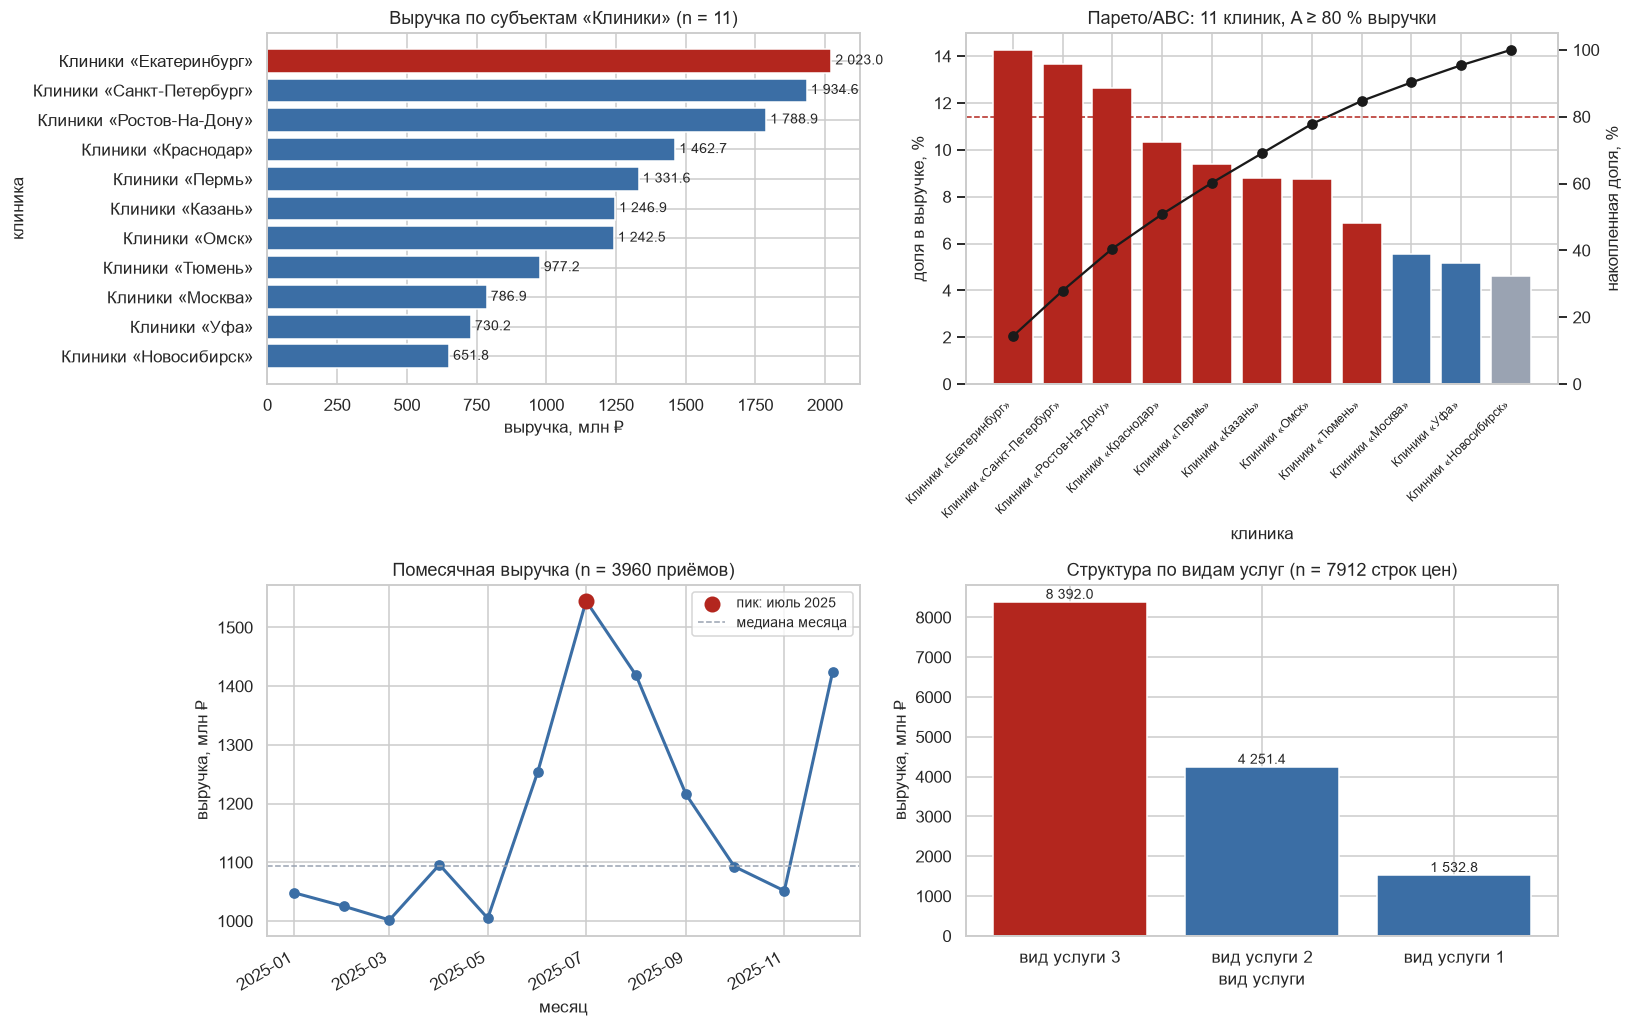

,entity_name,revenue,доля,накопленная доля,группа ABC
0,Клиники «Екатеринбург»,"2,022,964,816.04",0.14,0.14,A
1,Клиники «Санкт-Петербург»,"1,934,632,280.00",0.14,0.28,A
2,Клиники «Ростов-На-Дону»,"1,788,892,907.56",0.13,0.41,A
3,Клиники «Краснодар»,"1,462,744,128.04",0.10,0.51,A
4,Клиники «Пермь»,"1,331,574,117.45",0.09,0.60,A
5,Клиники «Казань»,"1,246,870,008.28",0.09,0.69,A
6,Клиники «Омск»,"1,242,466,129.62",0.09,0.78,A
7,Клиники «Тюмень»,"977,164,640.78",0.07,0.85,A
8,Клиники «Москва»,"786,897,454.92",0.06,0.90,B
9,Клиники «Уфа»,"730,201,418.78",0.05,0.95,B


Сходимость: клиники, месяцы, виды услуг и pandas дают один итог.


,entity_id,entity_name,appointments,patients,revenue,revenue_per_patient
0,E001,Клиники «Екатеринбург»,579,"122,220.00","2,022,964,816.04","16,551.83"
1,E002,Клиники «Санкт-Петербург»,546,"115,221.00","1,934,632,280.00","16,790.62"
2,E003,Клиники «Ростов-На-Дону»,489,"101,193.00","1,788,892,907.56","17,678.03"
3,E004,Клиники «Краснодар»,417,"87,945.00","1,462,744,128.04","16,632.49"
4,E005,Клиники «Пермь»,371,"77,617.00","1,331,574,117.45","17,155.70"
6,E007,Клиники «Омск»,354,"71,856.00","1,242,466,129.62","17,291.06"
5,E006,Клиники «Казань»,350,"71,481.00","1,246,870,008.28","17,443.38"
7,E008,Клиники «Тюмень»,265,"57,203.00","977,164,640.78","17,082.40"
8,E009,Клиники «Москва»,226,"45,816.00","786,897,454.92","17,175.17"
10,E011,Клиники «Уфа»,183,"41,280.00","730,201,418.78","17,688.99"



ВЫВОДЫ ПО ВАРИАНТУ 8 — МЕДИЦИНСКИЕ КЛИНИКИ
Корректная выручка: 14 176 208 192.25 ₽; наивный JOIN: 28 178 724 672.35 ₽.
Коэффициент завышения K = R_naive / R_correct = 1.9877.
Максимальное расхождение SQL и pandas по клинике: 0.0050 ₽.
Лидер по выручке: Клиники «Екатеринбург» (14.3%); топ-3 дают 40.5%.
Группа A: 8 клиник, накопленная доля 84.7%.
Пик: июль 2025, 1 545 018 324.84 ₽; минимум: март 2025, 1 001 684 790.98 ₽.
Ведущий вид услуги: вид услуги 3 (59.2% выручки).
По числу пациентов лидирует Клиники «Екатеринбург» (122 220);
наименьшая загрузка — Клиники «Новосибирск» (37 151).
В карантине 198 строк (дубли, дефектные приёмы и цены).
Ещё 7 пригодных приёмов не имеют цены и не входят в выручку.

УПРАВЛЕНЧЕСКИЕ РЕКОМЕНДАЦИИ
1. Проверить спрос и свободную мощность Клиники «Новосибирск», затем провести
   пилот расширения записи. Сценарий +5% пациентов при прежней выручке на пациента
   даёт около 32 590 015 ₽ в год; это условный эффект, не прогноз спроса.
   Проверка: пилот 4 недели, 

In [8]:
#@title Шаг 6. Аналитика и визуализация (эталон) { display-mode: "form" }
ACCENT, BASE, GREY = "#b3261e", "#3b6ea5", "#9aa3b2"
total_revenue = float(revenue_sql["revenue"].sum())

# ---------------------------------------------------------------- подготовка срезов
top = revenue_sql.sort_values("revenue", ascending=True)
pareto = revenue_sql.sort_values("revenue", ascending=False).copy()
pareto["доля"] = pareto["revenue"] / total_revenue
pareto["накопленная доля"] = pareto["доля"].cumsum()
pareto["группа ABC"] = np.where((pareto["накопленная доля"] - pareto["доля"]) < 0.8, "A",
                        np.where((pareto["накопленная доля"] - pareto["доля"]) < 0.95, "B", "C"))

monthly = (consolidated.assign(month=consolidated["event_date"].dt.to_period("M").dt.to_timestamp())
           .groupby("month", as_index=False)
           .agg(revenue=("event_revenue", "sum"), events=("event_id", "count")))

# Разрез по классам цен: выручку события делим между его ценовыми строками, иначе тот же
# fan-out завысит сумму. Проверка сходимости ниже обязана совпасть с итоговой выручкой.
by_class = (prices_valid.merge(events_valid[["event_id", "entity_id", "volume_units"]], on="event_id")
            .assign(n_rows=lambda d: d.groupby("event_id")["price_id"].transform("count"))
            .assign(revenue=lambda d: d["volume_units"] * d["unit_price"] / d["n_rows"])
            .groupby("price_class", as_index=False)["revenue"].sum()
            .sort_values("revenue", ascending=False))
class_gap = abs(float(by_class["revenue"].sum()) - total_revenue)
print(f"Контроль сходимости: сумма по разрезу «{CFG['cls']}» отличается от итоговой выручки "
      f"на {class_gap:.2f} ₽ (должно быть 0 с точностью округления)")

fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))

# 1. Выручка по субъектам, лидер выделен
ax = axes[0, 0]
colors = [ACCENT if i == len(top) - 1 else BASE for i in range(len(top))]
ax.barh(top["entity_name"], top["revenue"] / 1e6, color=colors)
for y, v in enumerate(top["revenue"] / 1e6):
    ax.text(v, y, f" {v:,.1f}".replace(",", " "), va="center", fontsize=9)
ax.set_title(f"Выручка по субъектам «{CFG['parent']}» (n = {len(top)})")
ax.set_xlabel("выручка, млн ₽"); ax.set_ylabel("клиника")

# 2. Диаграмма Парето и группы ABC
ax = axes[0, 1]
x = np.arange(len(pareto))
ax.bar(x, pareto["доля"] * 100, color=[{"A": ACCENT, "B": BASE, "C": GREY}[g] for g in pareto["группа ABC"]])
ax.set_xticks(x, pareto["entity_name"], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("доля в выручке, %")
ax2 = ax.twinx()
ax2.plot(x, pareto["накопленная доля"] * 100, color="#1a1a1a", marker="o", lw=1.5)
ax2.axhline(80, color=ACCENT, ls="--", lw=1)
ax2.set_ylim(0, 105); ax2.set_ylabel("накопленная доля, %"); ax2.grid(False)
n_a = int((pareto["группа ABC"] == "A").sum())
ax.set_title(f"Парето/ABC: {len(pareto)} клиник, A ≥ 80 % выручки")
ax.set_xlabel("клиника")

# 3. Сезонность
ax = axes[1, 0]
ax.plot(monthly["month"], monthly["revenue"] / 1e6, marker="o", color=BASE, lw=2)
RU_MONTHS = ["январь", "февраль", "март", "апрель", "май", "июнь",
             "июль", "август", "сентябрь", "октябрь", "ноябрь", "декабрь"]
def ru_month(ts):
    return f"{RU_MONTHS[ts.month - 1]} {ts.year}"
peak = monthly.loc[monthly["revenue"].idxmax()]
ax.scatter([peak["month"]], [peak["revenue"] / 1e6], color=ACCENT, s=90, zorder=3,
           label=f"пик: {ru_month(peak['month'])}")
ax.axhline(monthly["revenue"].median() / 1e6, color=GREY, ls="--", lw=1, label="медиана месяца")
ax.set_title(f"Помесячная выручка (n = {len(consolidated)} приёмов)")
ax.set_xlabel("месяц"); ax.set_ylabel("выручка, млн ₽"); ax.legend(fontsize=9)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

# 4. Структура по разрезу цен
ax = axes[1, 1]
ax.bar(by_class["price_class"], by_class["revenue"] / 1e6,
       color=[ACCENT if i == 0 else BASE for i in range(len(by_class))])
for i, v in enumerate(by_class["revenue"] / 1e6):
    ax.text(i, v, f"{v:,.1f}".replace(",", " "), ha="center", va="bottom", fontsize=9)
ax.set_title(f"Структура по видам услуг (n = {len(prices_valid)} строк цен)")
ax.set_xlabel("вид услуги"); ax.set_ylabel("выручка, млн ₽")
plt.tight_layout(); plt.show()
PLOTS_DONE = True

display(pareto[["entity_name", "revenue", "доля", "накопленная доля", "группа ABC"]].head(10))


# Дополнительный разрез варианта 8: загрузка клиник по приёмам и пациентам.
clinic_load = (consolidated.groupby(['entity_id', 'entity_name'], as_index=False)
               .agg(appointments=('event_id', 'count'),
                    patients=('volume_units', 'sum'),
                    revenue=('event_revenue', 'sum'))
               .sort_values('patients', ascending=False))
clinic_load['revenue_per_patient'] = clinic_load['revenue'] / clinic_load['patients']
clinic_load.to_csv(WORK / 'clinic_load.csv', index=False, encoding='utf-8-sig')
by_class.to_csv(WORK / 'revenue_by_service.csv', index=False, encoding='utf-8-sig')
monthly.to_csv(WORK / 'revenue_by_month.csv', index=False, encoding='utf-8-sig')
pareto.to_csv(WORK / 'clinic_abc.csv', index=False, encoding='utf-8-sig')
assert abs(float(revenue_pd['revenue'].sum()) - total_revenue) < 0.1
assert abs(float(monthly['revenue'].sum()) - total_revenue) < 0.1
assert abs(float(by_class['revenue'].sum()) - total_revenue) < 0.1
assert abs(float(clinic_load['revenue'].sum()) - total_revenue) < 0.1
print('Сходимость: клиники, месяцы, виды услуг и pandas дают один итог.')
display(clinic_load)

leader = pareto.iloc[0]
peak = monthly.loc[monthly['revenue'].idxmax()]
low = monthly.loc[monthly['revenue'].idxmin()]
service_leader = by_class.iloc[0]
share_top3 = float(pareto['доля'].head(3).sum())
service_share = float(service_leader['revenue'] / total_revenue)
load_top = clinic_load.iloc[0]
load_low = clinic_load.iloc[-1]
q_count = len(quarantine_duplicates) + len(quarantine_events) + len(quarantine_price)
scenario_gain = 0.05 * float(load_low['revenue'])
print(f"""
ВЫВОДЫ ПО ВАРИАНТУ 8 — МЕДИЦИНСКИЕ КЛИНИКИ
Корректная выручка: {nf(total_revenue, 2)} ₽; наивный JOIN: {nf(naive['revenue_naive'].sum(), 2)} ₽.
Коэффициент завышения K = R_naive / R_correct = {overstate:.4f}.
Максимальное расхождение SQL и pandas по клинике: {delta:.4f} ₽.
Лидер по выручке: {leader['entity_name']} ({leader['доля']:.1%}); топ-3 дают {share_top3:.1%}.
Группа A: {n_a} клиник, накопленная доля {pareto.loc[pareto['группа ABC']=='A', 'доля'].sum():.1%}.
Пик: {ru_month(peak['month'])}, {nf(peak['revenue'], 2)} ₽; минимум: {ru_month(low['month'])}, {nf(low['revenue'], 2)} ₽.
Ведущий вид услуги: {service_leader['price_class']} ({service_share:.1%} выручки).
По числу пациентов лидирует {load_top['entity_name']} ({nf(load_top['patients'])});
наименьшая загрузка — {load_low['entity_name']} ({nf(load_low['patients'])}).
В карантине {q_count} строк (дубли, дефектные приёмы и цены).
Ещё {len(unpriced_events)} пригодных приёмов не имеют цены и не входят в выручку.

УПРАВЛЕНЧЕСКИЕ РЕКОМЕНДАЦИИ
1. Проверить спрос и свободную мощность {load_low['entity_name']}, затем провести
   пилот расширения записи. Сценарий +5% пациентов при прежней выручке на пациента
   даёт около {nf(scenario_gain)} ₽ в год; это условный эффект, не прогноз спроса.
   Проверка: пилот 4 недели, число записей и пациентов, время ожидания и выручка
   на пациента; сравнить с сопоставимым периодом без расширения.
2. Запланировать персонал и материалы по месячному профилю, усилив {ru_month(peak['month'])}.
   Ожидаемый эффект — меньше отказов в пиковый месяц и меньше простаивающих смен
   в слабый месяц. Проверка: сравнение загрузки, отказов и выручки по месяцам
   с прошлым периодом при сопоставимом числе рабочих дней.
3. Закрепить расчёт через среднюю цену события и входной контроль ключей и цен.
   Ожидаемый эффект — устранение завышения отчётной выручки в {overstate:.2f} раза
   относительно наивного JOIN и сокращение доли карантина.
   Проверка: автоматическая сверка SQL/pandas, PRAGMA foreign_key_check и еженедельный
   отчёт о строках карантина.

ОГРАНИЧЕНИЯ
Данные синтетические: выводы показывают методику, а не деятельность реальных клиник.
Число пациентов здесь является объёмом учебного события; нет длительности приёма,
числа врачей, затрат, фактической загрузки расписания и объёма по виду услуги.
Разрез по видам услуг распределяет выручку события как v × p_i / n, поэтому он
иллюстрирует структуру модельной выручки, а не реальные продажи каждого вида услуги.
Выбросы по 3×IQR оставлены в расчёте: они требуют проверки первичного прейскуранта.
""")


**Интерпретация.** На диаграмме Парето смотрите, сколько субъектов попало в группу A: это и есть ответ на вопрос «где сосредоточено управленческое внимание». На сезонности сравните пик и провал: разрыв в полтора-два раза означает, что планирование по среднегодовому значению даст дефицит мощностей летом и простой зимой. В структуре по классам главное — строка контроля сходимости: ноль подтверждает, что при разрезании выручки вы не размножили её повторно.

Выводы для ЛПР — не пересказ графиков, а решения: что делать, на каком основании и как проверить результат.

## Шаг 7. BigQuery: пошаговое подключение из Colab

Показать, как та же витрина переносится в облачное хранилище, когда данных становится слишком много для одной машины.

### Шаг 1. Аккаунт и проект

1. Откройте <https://console.cloud.google.com> и войдите в аккаунт Google.
2. Вверху нажмите селектор проектов → **New Project**, задайте имя (например, `pw2-consolidation`) и создайте проект.
3. Скопируйте **Project ID** — это не название, а идентификатор вида `pw2-consolidation-123456`. Он понадобится в коде.

### Шаг 2. Режим работы: sandbox или биллинг

* **BigQuery sandbox** — без привязки карты. Бесплатно: 10 ГБ хранения и 1 ТБ обработанных запросами данных в месяц. Ограничения: нет DML-операций в части сценариев, таблицы автоматически удаляются через 60 дней. Для этой работы sandbox достаточно.
* **С биллингом** — снимаются ограничения sandbox, бесплатные лимиты те же. Карта привязывается в разделе **Billing**.

### Шаг 3. Включение API

В консоли: **APIs & Services → Library → BigQuery API → Enable**. Без этого библиотека вернёт ошибку доступа.

### Шаг 4. Аутентификация в Colab

```python
from google.colab import auth
auth.authenticate_user()     # откроется окно входа в Google-аккаунт
```

Вне Colab используется либо `gcloud auth application-default login`, либо ключ сервисного аккаунта: **IAM & Admin → Service Accounts → Create** → роль **BigQuery Data Editor** и **BigQuery Job User** → **Keys → Add key (JSON)**. Путь к файлу ключа кладётся в переменную окружения `GOOGLE_APPLICATION_CREDENTIALS`.

> Файл ключа — это пароль от проекта. Его нельзя коммитить в репозиторий и нельзя оставлять в выводе ячейки.

### Шаг 5. Датасет

Датасет — контейнер таблиц с привязкой к региону (`US`, `EU`, `europe-west3`). Регион выбирается один раз: соединять таблицы из разных регионов нельзя. Создаётся кодом в ячейке ниже (`create_dataset(..., exists_ok=True)`) или в консоли кнопкой **Create dataset**.

### Шаг 6. Загрузка и запрос

Код ячейки делает следующее:

1. загружает три очищенные таблицы через `load_table_from_dataframe` с режимом `WRITE_TRUNCATE` (перезапись — повторный запуск не плодит дубликаты);
2. выполняет **сухой прогон** (`dry_run=True`), который показывает, сколько байт прочитает запрос, ничего не тратя, — привычка, экономящая бюджет;
3. выполняет тот же корректный расчёт выручки, что и в SQLite;
4. сверяет результат с SQLite: цифры обязаны совпасть.

### Шаг 7. Стоимость и правила экономии

Оплата в BigQuery берётся за **объём прочитанных данных**, а не за время. Отсюда практические правила:

* не писать `SELECT *` — читаются только перечисленные колонки (колоночное хранение);
* использовать партиционирование по дате и кластеризацию по ключу фильтрации;
* перед тяжёлым запросом делать `dry_run`;
* учебные наборы этой работы весят единицы мегабайт, то есть укладываются в бесплатный лимит с огромным запасом.

### Отличия синтаксиса от SQLite

| | SQLite | BigQuery (GoogleSQL) |
|---|---|---|
| Идентификаторы | `"table"` или без кавычек | `` `project.dataset.table` `` |
| Типы дат | текст `YYYY-MM-DD` | `DATE`, `TIMESTAMP` |
| Приведение типа | `CAST(x AS REAL)` | `CAST(x AS FLOAT64)`, `SAFE_CAST` |
| Ключи | `PRIMARY KEY`, `FOREIGN KEY` | ограничения не проверяются: целостность обеспечивает конвейер |
| Пагинация | `LIMIT n OFFSET m` | `LIMIT n OFFSET m`, но для больших выборок — экспорт |

Последняя строка таблицы — важный профессиональный вывод: в аналитических хранилищах контроль качества не делегируется базе. Всё, что вы сделали на шагах 3–4, в промышленном контуре становится обязательным этапом конвейера.

In [9]:
#@title Шаг 7. Выгрузка витрины в BigQuery { display-mode: "form" }
# Ячейка ничего не делает, пока ENABLE_BIGQUERY = False в шаге 1.
# Перед включением выполните шаги из markdown-инструкции выше: проект, sandbox, датасет.
BQ_PROJECT_ID = "my-gcp-project"   #@param {type:"string"}
BQ_DATASET = "pw2_consolidation"   #@param {type:"string"}
BQ_LOCATION = "US"                 #@param ["US", "EU", "europe-west3", "asia-northeast1"]

if not ENABLE_BIGQUERY:
    print("BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: "
          "основная часть работы выполняется на SQLite.")
else:
    ensure("google-cloud-bigquery", "google.cloud.bigquery")
    ensure("pandas-gbq", "pandas_gbq")
    from google.cloud import bigquery

    # 1. Аутентификация: в Colab открывает окно входа в Google-аккаунт
    try:
        from google.colab import auth
        auth.authenticate_user()
        print("Аутентификация в Colab выполнена")
    except ImportError:
        print("Не Colab: используйте `gcloud auth application-default login` "
              "или переменную GOOGLE_APPLICATION_CREDENTIALS с путём к ключу сервисного аккаунта")

    client = bigquery.Client(project=BQ_PROJECT_ID, location=BQ_LOCATION)

    # 2. Датасет создаётся, если его ещё нет
    dataset_ref = bigquery.Dataset(f"{BQ_PROJECT_ID}.{BQ_DATASET}")
    dataset_ref.location = BQ_LOCATION
    client.create_dataset(dataset_ref, exists_ok=True)
    print(f"Датасет готов: {BQ_PROJECT_ID}.{BQ_DATASET} ({BQ_LOCATION})")

    # 3. Загрузка трёх очищенных таблиц
    for name, frame in [("entities", entities),
                        ("events", events_out),
                        ("prices", prices_valid[["price_id", "event_id", "unit_price", "price_class"]])]:
        job = client.load_table_from_dataframe(
            frame, f"{BQ_PROJECT_ID}.{BQ_DATASET}.{name}",
            job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE"))
        job.result()
        print(f"  загружено {name}: {nf(len(frame))} строк")

    # 4. Тот же корректный расчёт выручки, но на стороне BigQuery
    bq_sql = f"""
    WITH price_per_event AS (
        SELECT event_id, AVG(unit_price) AS avg_price
        FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.prices`
        GROUP BY event_id
    )
    SELECT e.entity_name,
           COUNT(ev.event_id)                            AS events_cnt,
           ROUND(SUM(ev.volume_units * pe.avg_price), 2) AS revenue
    FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.entities` e
    JOIN `{BQ_PROJECT_ID}.{BQ_DATASET}.events` ev ON ev.entity_id = e.entity_id
    JOIN price_per_event pe ON pe.event_id = ev.event_id
    GROUP BY e.entity_name
    ORDER BY revenue DESC
    """

    # 5. Сухой прогон: сколько байт прочитает запрос (в sandbox бесплатно 1 ТБ в месяц)
    dry = client.query(bq_sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
    print(f"\nОценка объёма чтения: {dry.total_bytes_processed / 1024**2:.2f} МБ "
          f"(бесплатный лимит — 1 ТБ в месяц)")

    revenue_bq = client.query(bq_sql).to_dataframe()
    display(revenue_bq.head(10))

    # 6. Сверка с SQLite: цифры обязаны совпасть
    check = (revenue_bq.set_index("entity_name")["revenue"]
             - revenue_sql.set_index("entity_name")["revenue"]).abs().max()
    print(f"Максимальное расхождение BigQuery и SQLite: {check:.4f}")

BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: основная часть работы выполняется на SQLite.


## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель; он подставляется в поле `VARIANT` шага 1 и определяет предметную область, объём генерации и набор дефектов (столбец «Дефекты»: ★ — базовый набор, ★★ — добавляются битые внешние ключи и отрицательные цены, ★★★ — ещё и дубликаты записей).

Архитектура данных во всех вариантах одинакова: справочник субъектов (CSV) → события с объёмом (XLSX) → цены по событиям, несколько строк на событие (JSON). Считается выручка по субъектам.

| № | Предметная область | CSV: справочник | XLSX: события | JSON: цены | Единица объёма | Разрез цен | Аналитическая задача | Дефекты |
|---:|---|---|---|---|---|---|---|:--:|
| 1 | Авиаперевозки | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют | ★★ |
| 2 | Розничная сеть | Магазины | Чеки | Позиции чека | единиц товара | категория товара | ABC-анализ магазинов: какие точки дают 80 % выручки | ★★★ |
| 3 | Логистика | Перевозчики | Отгрузки | Тарифы | паллет | тип тарифа | Загрузка перевозчиков: связь объёма и средней ставки | ★ |
| 4 | Телеком | Операторы | Сессии связи | Тарификация | минут | тарифный план | Доля тарифных планов в выручке и средний чек сессии | ★★ |
| 5 | Банковский ритейл | Отделения | Операции | Комиссии | транзакций | тип комиссии | Эффективность отделений: выручка на одну операцию | ★★★ |
| 6 | Гостиничный бизнес | Отели | Бронирования | Тарифы номеров | ночей | категория номера | Сезонность загрузки и вклад категорий номеров | ★ |
| 7 | Образовательные услуги | Центры | Группы | Стоимость обучения | слушателей | формат обучения | Выручка на слушателя и сравнение форматов | ★★ |
| 8 | Медицинские клиники | Клиники | Приёмы | Прейскурант | пациентов | вид услуги | Структура выручки по видам услуг и загрузка клиник | ★★★ |
| 9 | Энергосбыт | Сбытовые компании | Поставки | Тарифы | МВт·ч | категория потребителя | Концентрация выручки по категориям потребителей | ★ |
| 10 | Маркетплейс | Продавцы | Заказы | Цены товаров | единиц | категория товара | Топ продавцов и доля категорий в обороте | ★★ |
| 11 | Общественный транспорт | Перевозчики | Маршруты-рейсы | Тарифы проезда | пассажиров | тип билета | Выручка по типам билетов и пиковые месяцы | ★★★ |
| 12 | Страхование | Агентства | Договоры | Тарифные ставки | объектов | вид страхования | Средняя премия по видам страхования и вклад агентств | ★ |
| 13 | Грузовые ж/д перевозки | Операторы вагонов | Отправки | Ставки | тонн | род груза | Доходность по родам груза и сезонность отправок | ★★ |
| 14 | Общепит | Рестораны | Заказы | Цены блюд | порций | категория меню | Средний чек и вклад категорий меню | ★★★ |
| 15 | Фитнес-сети | Клубы | Визиты и покупки | Прайс услуг | услуг | тип абонемента | Выручка на клуб и структура абонементов | ★ |
| 16 | Аренда спецтехники | Парки техники | Смены аренды | Ставки аренды | машино-часов | тип техники | Утилизация парка и доходность типов техники | ★★ |
| 17 | Курьерская доставка | Службы доставки | Доставки | Тарифы | посылок | скорость доставки | Доля экспресс-доставки в выручке | ★★★ |
| 18 | Оптовая торговля | Дистрибьюторы | Поставки | Прайс-листы | коробов | товарная группа | Парето по товарным группам и вклад дистрибьюторов | ★ |
| 19 | Автосервис | Сервисные центры | Заказ-наряды | Прейскурант работ | нормо-часов | вид работ | Выручка по видам работ и загрузка центров | ★★ |
| 20 | Цифровые подписки | Сервисы | Подписки | Тарифные планы | подписчиков | план подписки | Структура подписной базы и выручка на подписчика | ★★★ |
| 21 | Сельхозпроизводство | Хозяйства | Партии отгрузки | Закупочные цены | тонн | культура | Доходность культур и сезонность отгрузок | ★ |
| 22 | Строительный ритейл | Гипермаркеты | Продажи | Цены материалов | единиц | группа материалов | Сезонность продаж и вклад групп материалов | ★★ |
| 23 | Морские перевозки | Судоходные линии | Рейсы судов | Фрахтовые ставки | TEU | тип контейнера | Доходность линий и структура по типам контейнеров | ★★★ |
| 24 | Аптечные сети | Аптеки | Продажи | Цены препаратов | упаковок | группа препаратов | Вклад товарных групп и сравнение точек | ★ |
| 25 | Кинотеатры | Кинотеатры | Сеансы | Цены билетов | зрителей | тип сеанса | Заполняемость залов и выручка по типам сеансов | ★★ |
| 26 | Промышленное производство | Заводы | Партии продукции | Отпускные цены | тонн | марка продукции | Вклад марок продукции и сезонность отгрузок | ★★★ |
| 27 | Рекламные площадки | Площадки | Кампании | Ставки размещения | показов (тыс.) | формат размещения | Доходность форматов и концентрация выручки | ★ |
| 28 | ЖКХ | Управляющие компании | Начисления | Тарифы услуг | объектов | вид услуги | Структура начислений и сравнение управляющих компаний | ★★ |
| 29 | Каршеринг | Операторы | Поездки | Тарифы поездок | минут | класс автомобиля | Выручка на поездку и вклад классов автомобилей | ★★★ |
| 30 | Авиаперевозки (эталон преподавателя) | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки | ★ |

Минимум для зачёта: найдено не менее пяти проблем качества, заполнен журнал очистки, показана разница наивного и корректного расчёта, результаты SQL и pandas сошлись.

## Критерии оценивания (10 баллов)

| Блок | Что проверяется | Максимум |
|---|---|---:|
| 1. Источники и загрузка | Три формата прочитаны корректно, без потери ведущих нулей и «умного» приведения типов | 1,0 |
| 2. Аудит качества | Профиль источников; журнал проблем по шести измерениям с числом затронутых строк; расчёт кардинальности связей | 2,0 |
| 3. Очистка | Журнал изменений; карантин вместо тихого удаления; пропуски не заменены нулями; разбор обоих форматов дат и чисел с валютой | 2,0 |
| 4. Модель данных и SQL | Схема с PK, FK, `CHECK` и индексами; `PRAGMA foreign_keys`; корректный запрос с CTE; сверка SQL и pandas | 2,5 |
| 5. Аналитика и визуализация | Четыре среза по варианту; контроль сходимости срезов; оформление графиков | 1,5 |
| 6. Выводы | Решения с основанием, ожидаемым эффектом и способом проверки; названы ограничения данных | 1,0 |

### Шкала

| Баллы | Оценка |
|---|---|
| 9–10 | **A** — конвейер воспроизводим, качество данных проработано, выводы управленческие |
| 8–9 | **B** — данные консолидированы верно, есть недочёты в аудите или оформлении |
| 7–8 | **C** — расчёт верен, но качество данных проработано формально |
| 6–7 | **D** — есть результат, но методика расчёта или очистки содержит ошибки |
| < 6 | **F** — выручка посчитана наивным JOIN, дефекты не найдены, работа не воспроизводится |

### Обязательные требования

1. Расчёт выручки выполнен **после** свёртки цен до уровня события; коэффициент завышения наивного варианта показан числом.
2. Результаты SQL и pandas сходятся с точностью округления.
3. Ни одна строка не удалена без записи в журнале очистки.
4. Пропуски остались пропусками.
5. Все графики подписаны: заголовок с объёмом выборки, оси с единицами измерения.
6. Сумма по любому аналитическому разрезу совпадает с итоговой выручкой.

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Выручка посчитана наивным соединением, эффект fan-out не обнаружен | −2,5 |
| `NaN` заменены нулями «чтобы считалось» | −1,0 |
| Строки удалены без журнала и карантина | −1,0 |
| Нет внешних ключей и ограничений в схеме | −1,0 |
| Расхождение SQL и pandas не объяснено | −1,0 |
| Графики без подписей осей и единиц | −0,5 |
| Ноутбук сдан без выводов ячеек | −1,0 |
| Ключ сервисного аккаунта Google в репозитории | −1,5 и обязательный отзыв ключа |

In [10]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Вариант выбран корректно", 1 <= VARIANT <= 30)
check("Созданы три источника разных форматов",
      all((DATA / f).exists() for f in ("entities.csv", "events.xlsx", "prices.json")))
check("Проведён аудит качества (журнал не пуст)", len(globals().get("issues", [])) >= 5,
      "найдите проблемы по всем шести измерениям качества")
check("Журнал очистки заполнен", len(globals().get("CLEAN_LOG", [])) >= 4)
check("Пропуски не заменены нулями",
      float(events_valid["volume_units"].min()) > 0 and float(prices_valid["unit_price"].min()) > 0)
check("Нарушения целостности вынесены в карантин, а не удалены молча",
      "quarantine_fk" in globals() and "quarantine_price" in globals())
check("База SQLite создана и заполнена", DB_PATH.exists() and DB_PATH.stat().st_size > 20000)
check("Внешние ключи и ограничения объявлены",
      "REFERENCES" in "".join(r[0] for r in conn.execute(
          "SELECT sql FROM sqlite_master WHERE type='table'").fetchall() if r[0]))
check("Показана разница наивного и корректного расчёта", globals().get("overstate", 0) > 1.05,
      "наивный JOIN обязан завышать выручку — покажите это числом")
check("SQL и pandas сошлись", globals().get("delta", 1e9) < 1.0,
      "расхождение больше рубля означает разную методику расчёта")
check("Построены графики", len(plt.get_fignums()) > 0 or globals().get("PLOTS_DONE", False))

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Вариант выбран корректно
  ✅ Созданы три источника разных форматов
  ✅ Проведён аудит качества (журнал не пуст)
  ✅ Журнал очистки заполнен
  ✅ Пропуски не заменены нулями
  ✅ Нарушения целостности вынесены в карантин, а не удалены молча
  ✅ База SQLite создана и заполнена
  ✅ Внешние ключи и ограничения объявлены
  ✅ Показана разница наивного и корректного расчёта
  ✅ SQL и pandas сошлись
  ✅ Построены графики


## Задание со звёздочкой (до +2 баллов)

Учебная витрина собирается один раз. Промышленная — обновляется, хранит историю и проверяет себя сама. Выберите одно направление и доведите до измеримого результата.

In [11]:
#@title ★ C. Эксперимент: положительный и четыре отрицательных пакета
baseline = validate_clean_batch(entities, events_valid, prices_valid)
counts_before = dict(conn.execute("SELECT 'entities', COUNT(*) FROM entities UNION ALL "
                                  "SELECT 'events', COUNT(*) FROM events UNION ALL "
                                  "SELECT 'prices', COUNT(*) FROM prices").fetchall())
assert baseline['entities'] == counts_before['entities']
assert baseline['events'] == counts_before['events']
assert baseline['prices'] == counts_before['prices']

bad_cases = []
p_bad = prices_valid.copy()
p_bad.loc[p_bad.index[0], 'unit_price'] = -1
bad_cases.append(('отрицательная цена', entities, events_valid, p_bad))
e_bad = events_valid.copy()
e_bad.loc[e_bad.index[0], 'entity_id'] = 'E999'
bad_cases.append(('сирота по клинике', entities, e_bad, prices_valid))
p_dup = pd.concat([prices_valid, prices_valid.iloc[[0]]], ignore_index=True)
bad_cases.append(('повтор price_id', entities, events_valid, p_dup))
e_null = events_valid.copy()
e_null.loc[e_null.index[0], 'volume_units'] = np.nan
bad_cases.append(('пропуск объёма', entities, e_null, prices_valid))

results = [{'сценарий': 'очищенный пакет', 'результат': 'принят', 'причина': 'все критичные правила пройдены'}]
for name, ent, ev, pr in bad_cases:
    try:
        validate_clean_batch(ent, ev, pr)
    except AssertionError as exc:
        results.append({'сценарий': name, 'результат': 'остановлен до INSERT', 'причина': str(exc)})
    else:
        raise AssertionError(f'Автотест пропустил дефект: {name}')
counts_after = dict(conn.execute("SELECT 'entities', COUNT(*) FROM entities UNION ALL "
                                 "SELECT 'events', COUNT(*) FROM events UNION ALL "
                                 "SELECT 'prices', COUNT(*) FROM prices").fetchall())
assert counts_before == counts_after, 'Негативный тест изменил БД'
assert conn.execute('PRAGMA foreign_key_check').fetchall() == []
dq_test_results = pd.DataFrame(results)
dq_test_results.to_csv(WORK / 'dq_test_results.csv', index=False, encoding='utf-8-sig')
display(dq_test_results)
print('Бонус C: 1 корректный пакет принят, 4 дефектных остановлены до INSERT; число строк в БД не изменилось.')
DQ_TESTS_OK = True


,сценарий,результат,причина
0,очищенный пакет,принят,все критичные правила пройдены
1,отрицательная цена,остановлен до INSERT,Некорректная цена
2,сирота по клинике,остановлен до INSERT,Неизвестная клиника
3,повтор price_id,остановлен до INSERT,prices: повтор ключа
4,пропуск объёма,остановлен до INSERT,Пропуск в приёмах


Бонус C: 1 корректный пакет принят, 4 дефектных остановлены до INSERT; число строк в БД не изменилось.
